## Push this project to GitHub

Open PowerShell in this project folder and run:

```powershell
git add .
git commit -m "Describe your changes"
git push
```

For the first upload, initialize Git and connect the repository first. The raw `asl_alphabet_train/` dataset is excluded by `.gitignore` because it is too large for a normal GitHub upload. If GitHub has changes that are not on your computer, run `git pull --no-rebase origin main --allow-unrelated-histories`, resolve any conflicts, commit the merge, and then run `git push`.

| Cell | Description |

| 1 | Import libraries, configure folders and reproducibility, create artifact folders, and select GPU/CPU. |
| 2 | Audit the training, Kaggle-test, and webcam-test folder structures and image counts. |
| 3 | Display one random Kaggle training image for each of the 29 classes. |
| 4 | Create and save a reproducible stratified training/validation split. |
| 5 | Define disk-based datasets, image transformations, and PyTorch data loaders. |
| 6 | Preview the training augmentations applied to a representative image. |
| 7 | Benchmark data-loading and GPU-transfer speed before model training. |
| 8 | Define and verify a small custom CNN baseline model. |
| 9 | Define shared training, validation, checkpointing, and resume helper functions. |
| 10 | Run a short baseline-CNN smoke test to verify loss, accuracy, GPU use, and checkpoint saving. |
| 11 | Train or resume the baseline CNN with ten-minute progress updates and checkpoints. |
| 12 | Plot baseline-CNN learning curves and evaluate its validation accuracy, F1 score, and confusion matrix. |
| 13 | Define a MobileNetV3-Small transfer-learning model for comparison. |
| 14 | Run a short MobileNet smoke test and estimate full-training runtime. |
| 15 | Train or resume MobileNet with the same checkpointing and progress system. |
| 16 | Compare CNN and MobileNet validation metrics to select the final model. |
| 17 | Evaluate the selected model on the 29-image Kaggle test folder as a sanity check. |
| 18 | Audit and build a loader for the held-out personal webcam test dataset. |
| 19 | Evaluate the selected model on the held-out personal webcam images. |
| 20 | Save final metrics, plots, model weights, and a report-ready results summary. |
| 21 | Configure the live webcam inference settings, including confidence and hold-time thresholds. |
| 22 | Run the OpenCV real-time sign-recognition program and save recognized text to a file. |

Markdown #1

### Purpose
This cell imports the libraries used throughout the project, defines the project folders, sets reproducibility values, creates folders for saved outputs and checkpoints, and checks whether PyTorch can use the NVIDIA GPU.

### Why it is needed
Every later cell depends on these shared variables. Defining paths and settings once avoids repeated hard-coded values and makes the project easier to reproduce. The device check determines whether training will use the RTX 4060 GPU or fall back to the CPU.

In [2]:
# Python Cell #1

# Expected runtime: about 0 minutes (typically a few seconds).
# Rerun status: Safe to rerun only if configuration values are unchanged. If you change a path, seed, or setting here, rerun all following cells.

import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from pathlib import Path
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch

# Reproducibility settings
SEED = 4452
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Use deterministic behavior when possible so repeated runs are more comparable.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Project folders: this notebook should be saved in the Main Project folder.
PROJECT_ROOT = Path.cwd()
TRAIN_DIR = PROJECT_ROOT / "asl_alphabet_train" / "asl_alphabet_train"
KAGGLE_TEST_DIR = PROJECT_ROOT / "asl_alphabet_test" / "asl_alphabet_test"
WEBCAM_TEST_DIR = PROJECT_ROOT / "our_hands_testing_pictures"

# Folders created by this notebook for recoverable project outputs.
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
CHECKPOINT_DIR = ARTIFACTS_DIR / "checkpoints"
RESULTS_DIR = ARTIFACTS_DIR / "results"

for folder in (ARTIFACTS_DIR, CHECKPOINT_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Use the GPU when PyTorch can access it; otherwise, use the CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

print(f"Python environment: {platform.python_version()}")
print(f"PyTorch version:     {torch.__version__}")
print(f"Selected device:     {DEVICE}")

if DEVICE.type == "cuda":
    print(f"GPU:                 {torch.cuda.get_device_name(0)}")
    print(f"GPU memory:          {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
else:
    print("WARNING: CUDA was not detected. Training will use the CPU unless PyTorch/CUDA is configured later.")

print("\nProject folders:")
for name, folder in {
    "Training data": TRAIN_DIR,
    "Kaggle test data": KAGGLE_TEST_DIR,
    "Webcam test data": WEBCAM_TEST_DIR,
    "Checkpoints": CHECKPOINT_DIR,
}.items():
    print(f"{name:<18}: {folder}")

assert TRAIN_DIR.is_dir(), f"Training folder was not found: {TRAIN_DIR}"
assert KAGGLE_TEST_DIR.is_dir(), f"Kaggle test folder was not found: {KAGGLE_TEST_DIR}"
assert WEBCAM_TEST_DIR.is_dir(), f"Webcam test folder was not found: {WEBCAM_TEST_DIR}"

Python environment: 3.14.6
PyTorch version:     2.14.1+cpu
Selected device:     cpu

Project folders:
Training data     : c:\Users\Finnm\OneDrive - Cal Poly\Senior Year\ME 4452 - Machine Learning\Lab\Main Project\asl_alphabet_train\asl_alphabet_train
Kaggle test data  : c:\Users\Finnm\OneDrive - Cal Poly\Senior Year\ME 4452 - Machine Learning\Lab\Main Project\asl_alphabet_test\asl_alphabet_test
Webcam test data  : c:\Users\Finnm\OneDrive - Cal Poly\Senior Year\ME 4452 - Machine Learning\Lab\Main Project\our_hands_testing_pictures
Checkpoints       : c:\Users\Finnm\OneDrive - Cal Poly\Senior Year\ME 4452 - Machine Learning\Lab\Main Project\artifacts\checkpoints


Markdown #2

### Purpose
This cell creates any missing personal-webcam class folders, verifies the 29 expected training labels, counts the Kaggle training images in each class, counts the 29-image Kaggle test set, and counts the current personal webcam test images.

### Why it is needed
The personal webcam dataset is still being assembled. Automatically creating missing empty class folders prevents setup errors while preserving the required 29-class structure. This cell does not load image pixels into memory.

In [3]:
# Python Cell #2

# Expected runtime: about 1 minute.
# Rerun status: Safe to rerun. It creates only missing webcam folders and recounts images; rerun Cell 3 afterward only if you want to display new samples.

import string

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
CLASS_NAMES = list(string.ascii_uppercase) + ["del", "nothing", "space"]
NUM_CLASSES = len(CLASS_NAMES)

def count_images(folder):
    """Count image files without loading their pixels into memory."""
    return sum(
        1 for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )

# Create any webcam-test class folders that have not been created yet.
created_folders = []
for class_name in CLASS_NAMES:
    class_folder = WEBCAM_TEST_DIR / class_name
    if not class_folder.exists():
        class_folder.mkdir()
        created_folders.append(class_name)

if created_folders:
    print("Created missing webcam class folders:", ", ".join(created_folders))
else:
    print("All webcam class folders already exist.")

# Training data must already contain exactly the expected labels.
train_class_folders = sorted(path.name for path in TRAIN_DIR.iterdir() if path.is_dir())
missing_train = sorted(set(CLASS_NAMES) - set(train_class_folders))
unexpected_train = sorted(set(train_class_folders) - set(CLASS_NAMES))

assert not missing_train and not unexpected_train, (
    "Training-data class folders do not match the expected 29 labels.\n"
    f"Missing: {missing_train}\n"
    f"Unexpected: {unexpected_train}"
)

train_counts = {
    class_name: count_images(TRAIN_DIR / class_name)
    for class_name in CLASS_NAMES
}

webcam_counts = {
    class_name: count_images(WEBCAM_TEST_DIR / class_name)
    for class_name in CLASS_NAMES
}

kaggle_test_count = count_images(KAGGLE_TEST_DIR)

dataset_summary = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Kaggle training images": [train_counts[name] for name in CLASS_NAMES],
    "Personal webcam test images": [webcam_counts[name] for name in CLASS_NAMES],
})

display(dataset_summary)

print(f"Expected classes:              {NUM_CLASSES}")
print(f"Total Kaggle training images:  {sum(train_counts.values()):,}")
print(f"Kaggle test images:            {kaggle_test_count:,}")
print(f"Personal webcam test images:   {sum(webcam_counts.values()):,}")

if kaggle_test_count == NUM_CLASSES:
    print("\nKaggle test check passed: 29 images were found.")
else:
    print("\nWARNING: The Kaggle test folder does not contain exactly 29 images.")

if sum(webcam_counts.values()) == 0:
    print("Webcam test folders are ready but do not contain images yet.")
elif min(webcam_counts.values()) < 5:
    print("Webcam test set is incomplete: at least one class has fewer than 5 images.")
else:
    print("Webcam test set currently has at least 5 images in every class.")

All webcam class folders already exist.


,Class,Kaggle training images,Personal webcam test images
0,A,3000,0
1,B,3000,0
2,C,3000,0
3,D,3000,0
4,E,3000,0
5,F,3000,0
6,G,3000,0
7,H,3000,0
8,I,3000,0
9,J,3000,0


Expected classes:              29
Total Kaggle training images:  87,000
Kaggle test images:            28
Personal webcam test images:   0

Webcam test folders are ready but do not contain images yet.


Markdown #3

### Purpose
This cell displays one randomly selected Kaggle training image from every one of the 29 classes in a five-column grid. It also shows each image’s original dimensions.

### Why it is needed
Viewing every class confirms that each folder label corresponds to the correct hand sign and reveals the range of image framing, lighting, and orientation before training begins.

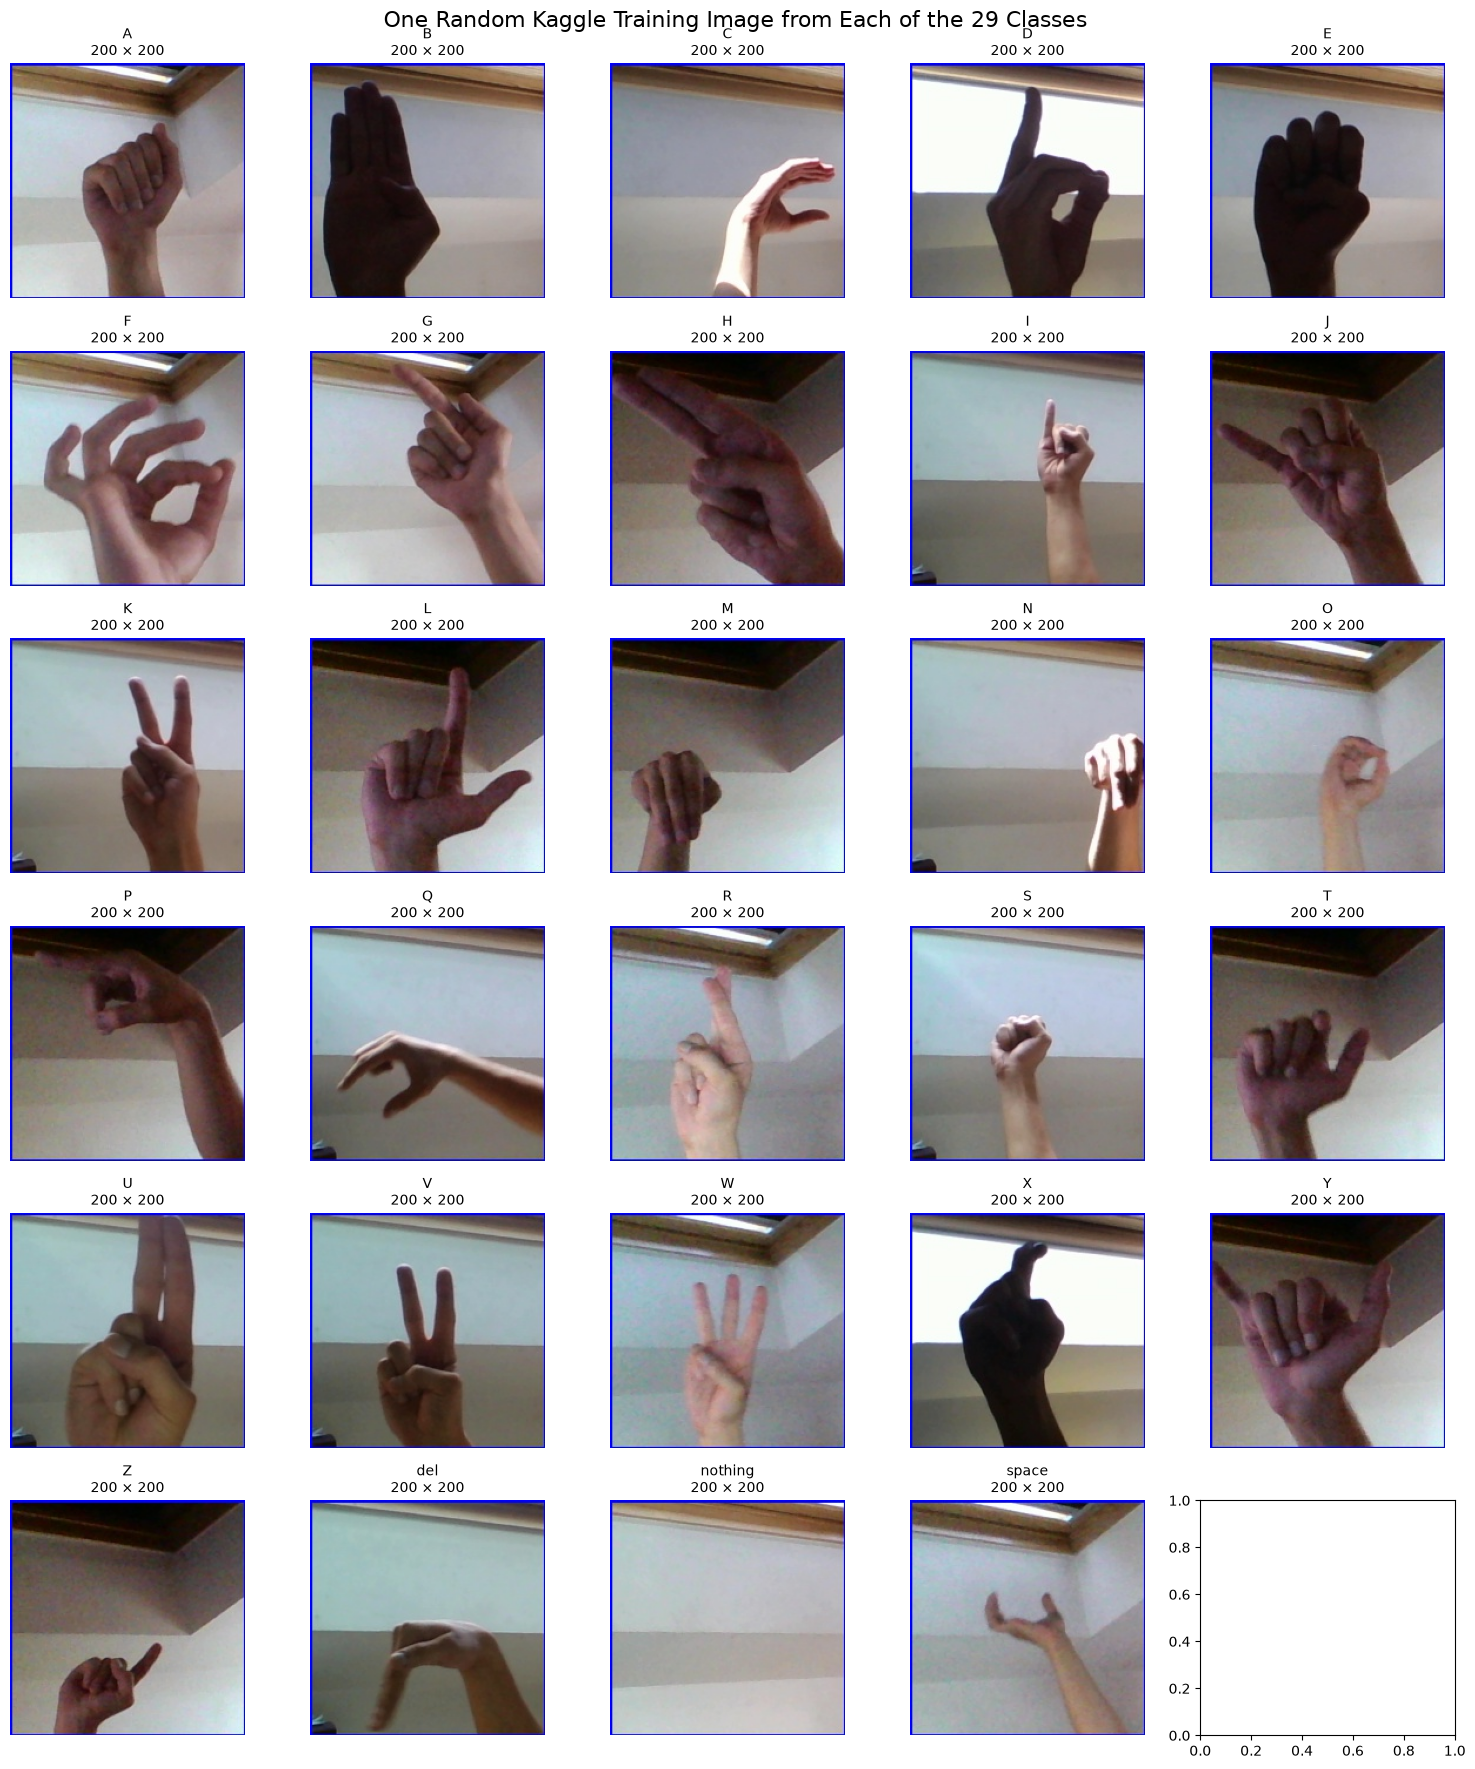

In [4]:
# Python Cell #3

# Expected runtime: about 0 minutes (typically a few seconds).
# Rerun status: Safe to rerun. No following cells need to be rerun because this cell only displays existing training images.

rng = np.random.default_rng(SEED)

NUM_COLUMNS = 5
NUM_ROWS = int(np.ceil(NUM_CLASSES / NUM_COLUMNS))

fig, axes = plt.subplots(NUM_ROWS, NUM_COLUMNS, figsize=(15, 3 * NUM_ROWS))
axes = axes.flat

for axis, class_name in zip(axes, CLASS_NAMES):
    class_images = sorted(
        path for path in (TRAIN_DIR / class_name).iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    selected_path = class_images[rng.integers(len(class_images))]

    with Image.open(selected_path) as image:
        image_copy = image.convert("RGB").copy()

    axis.imshow(image_copy)
    axis.set_title(
        f"{class_name}\n{image_copy.size[0]} × {image_copy.size[1]}",
        fontsize=10
    )
    axis.axis("off")

# Hide the one unused subplot because 29 classes do not fill a 5-column grid evenly.
for axis in list(axes)[NUM_CLASSES:]:
    axis.axis("off")

fig.suptitle("One Random Kaggle Training Image from Each of the 29 Classes", fontsize=16)
plt.tight_layout()
plt.show()

Markdown #4

### Purpose
This cell creates a reproducible 80% training and 20% validation split from the Kaggle training folders. It saves the split as a CSV file in the `artifacts` folder so every future training run uses the exact same images for training and validation.

### Why it is needed
The Kaggle test folder has only one image per class, so it is not large enough to guide model selection. The validation set provides a much more meaningful way to compare models and choose the best checkpoint. Saving the split prevents accidental changes to the validation images between runs.

In [5]:
# Python Cell #4

# Expected runtime: about 2 minutes the first time; about 0 minutes on later runs.
# Rerun status: Safe to rerun. It loads the existing saved split by default. If you set REBUILD_SPLIT = True, all later data-loading, training, and evaluation cells must be rerun.

VALIDATION_FRACTION = 0.20
SPLIT_FILE = ARTIFACTS_DIR / "train_validation_split.csv"
REBUILD_SPLIT = False

if SPLIT_FILE.exists() and not REBUILD_SPLIT:
    split_table = pd.read_csv(SPLIT_FILE)
    print(f"Loaded existing saved split: {SPLIT_FILE.name}")
else:
    split_records = []

    for class_index, class_name in enumerate(CLASS_NAMES):
        image_names = sorted(
            path.name for path in (TRAIN_DIR / class_name).iterdir()
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        )

        assert len(image_names) >= 2, (
            f"Class '{class_name}' needs at least two images to create "
            "training and validation subsets."
        )

        # A separate seeded generator per class keeps the split reproducible.
        class_rng = np.random.default_rng(SEED + class_index)
        shuffled_indices = class_rng.permutation(len(image_names))

        validation_count = max(1, int(round(len(image_names) * VALIDATION_FRACTION)))
        validation_indices = set(shuffled_indices[:validation_count])

        for image_index, image_name in enumerate(image_names):
            split_records.append({
                "class_name": class_name,
                "image_name": image_name,
                "split": "validation" if image_index in validation_indices else "training",
            })

    split_table = pd.DataFrame(split_records)
    split_table.to_csv(SPLIT_FILE, index=False)
    print(f"Created and saved a new split: {SPLIT_FILE.name}")

split_summary = (
    split_table
    .groupby(["class_name", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(CLASS_NAMES)
)

split_summary["total"] = split_summary.sum(axis=1)
display(split_summary)

print(f"Total training images:   {(split_table['split'] == 'training').sum():,}")
print(f"Total validation images: {(split_table['split'] == 'validation').sum():,}")
print(f"Validation fraction:     {VALIDATION_FRACTION:.0%}")

Loaded existing saved split: train_validation_split.csv


split,training,validation,total
class_name,,,
A,2400,600,3000
B,2400,600,3000
C,2400,600,3000
D,2400,600,3000
E,2400,600,3000
F,2400,600,3000
G,2400,600,3000
H,2400,600,3000
I,2400,600,3000


Total training images:   69,600
Total validation images: 17,400
Validation fraction:     20%


Markdown #4

### Purpose
This cell defines PyTorch datasets and data loaders that read images from disk in small batches. It applies moderate image augmentation to training images and consistent preprocessing to validation images, then loads one batch to verify that the images and labels are correct.

### Why it is needed
Loading images in batches prevents the full 87,000-image dataset from occupying RAM or causing a long startup delay. Training augmentation helps the model tolerate modest changes in lighting, hand position, and scale. Validation images are not augmented so their evaluation remains consistent and fair.

In [6]:
# Python Cell #5

# Expected runtime: about 0 minutes (typically a few seconds).
# Rerun status: Safe to rerun. It recreates the datasets and data loaders. If you change IMAGE_SIZE, BATCH_SIZE, or transformations, rerun all later model-training and evaluation cells.

from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Image and loader settings. A batch size of 32 is conservative for the RTX 4060's 8 GB VRAM.
IMAGE_SIZE = 160
BATCH_SIZE = 32
NUM_WORKERS = 0  # Most reliable setting for Windows Jupyter notebooks; can be benchmarked later.

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 16, IMAGE_SIZE + 16)),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.20, contrast=0.20, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

validation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class ASLSignDataset(Dataset):
    """Loads ASL images defined by the saved training/validation split."""

    def __init__(self, split_name, transform):
        self.records = (
            split_table.loc[split_table["split"] == split_name]
            .reset_index(drop=True)
        )
        self.transform = transform
        self.class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records.iloc[index]
        image_path = TRAIN_DIR / record["class_name"] / record["image_name"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = self.class_to_index[record["class_name"]]
        return image, label

train_dataset = ASLSignDataset("training", train_transform)
validation_dataset = ASLSignDataset("validation", validation_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=torch.Generator().manual_seed(SEED),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

images, labels = next(iter(train_loader))

print(f"Training images:   {len(train_dataset):,}")
print(f"Validation images: {len(validation_dataset):,}")
print(f"One image batch:   {tuple(images.shape)}")
print(f"One label batch:   {tuple(labels.shape)}")
print(f"Example labels:    {[CLASS_NAMES[label] for label in labels[:10].tolist()]}")

Training images:   69,600
Validation images: 17,400
One image batch:   (32, 3, 160, 160)
One label batch:   (32,)
Example labels:    ['nothing', 'space', 'J', 'U', 'G', 'C', 'K', 'K', 'nothing', 'W']


Markdown #6

### Purpose
This cell displays one original training image alongside five differently augmented versions of that same image.

### Why it is needed
The training model will see augmented images rather than only the original Kaggle images. This visual check confirms that the transformations introduce useful variation in crop, rotation, brightness, and contrast without making the hand sign unrecognizable.

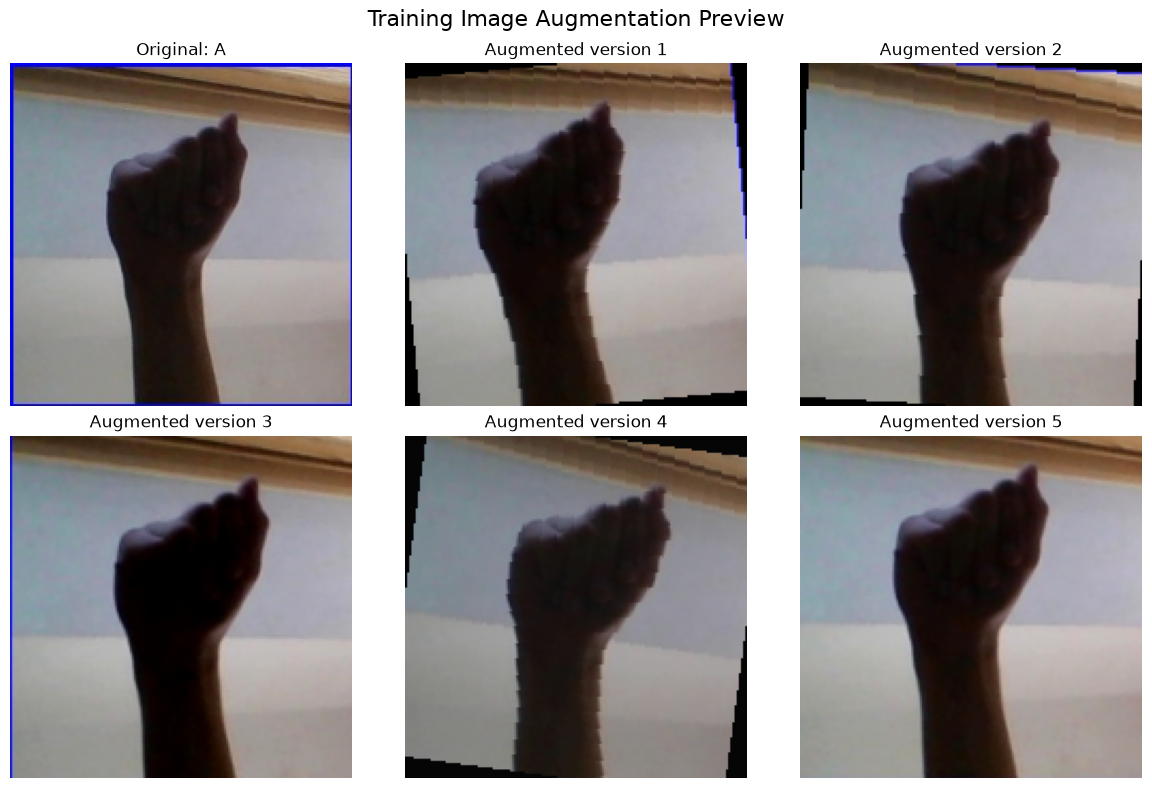

Source image: A1.jpg
Class label:  A


In [7]:
# Python Cell 6

# Expected runtime: about 0 minutes (typically a few seconds).
# Rerun status: Safe to rerun. It only creates a visualization; no following cells need to be rerun.

SAMPLE_INDEX = 0

record = train_dataset.records.iloc[SAMPLE_INDEX]
sample_path = TRAIN_DIR / record["class_name"] / record["image_name"]

with Image.open(sample_path) as original_image:
    original_image = original_image.convert("RGB").copy()

def denormalize_image(image_tensor):
    """Convert a normalized PyTorch image tensor into a displayable NumPy image."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    image_tensor = image_tensor.cpu() * std + mean
    image_tensor = image_tensor.clamp(0, 1)

    return image_tensor.permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flat

axes[0].imshow(original_image)
axes[0].set_title(f"Original: {record['class_name']}")
axes[0].axis("off")

for augmentation_number, axis in enumerate(list(axes)[1:], start=1):
    augmented_image = train_transform(original_image)
    axis.imshow(denormalize_image(augmented_image))
    axis.set_title(f"Augmented version {augmentation_number}")
    axis.axis("off")

fig.suptitle("Training Image Augmentation Preview", fontsize=16)
plt.tight_layout()
plt.show()

print(f"Source image: {sample_path.name}")
print(f"Class label:  {record['class_name']}")

Markdown #7

### Purpose
This cell benchmarks the image data loader and GPU-transfer speed using a small number of training batches. It prints progress during the test and reports the average image-loading rate.

### Why it is needed
The training set contains approximately 87,000 images, so data loading from OneDrive can become a performance bottleneck. This test verifies that the training pipeline can read and transfer batches correctly before a model is trained for a long time.

In [8]:
# Python Cell 7

# Expected runtime: about 1 minute.
# Rerun status: Safe to rerun. It does not train or modify a model. No following cells need to be rerun unless you change NUM_WORKERS or BATCH_SIZE in Cell 5.

LOADER_BENCHMARK_BATCHES = min(50, len(train_loader))
PROGRESS_INTERVAL = 10

if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

start_time = time.perf_counter()
images_processed = 0

for batch_number, (images, labels) in enumerate(train_loader, start=1):
    images = images.to(DEVICE, non_blocking=PIN_MEMORY)
    labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)

    images_processed += len(images)

    if batch_number % PROGRESS_INTERVAL == 0 or batch_number == LOADER_BENCHMARK_BATCHES:
        elapsed_seconds = time.perf_counter() - start_time
        print(
            f"Processed {batch_number:>2}/{LOADER_BENCHMARK_BATCHES} batches "
            f"({images_processed:,} images) in {elapsed_seconds:.1f} seconds."
        )

    if batch_number == LOADER_BENCHMARK_BATCHES:
        break

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

elapsed_seconds = time.perf_counter() - start_time
images_per_second = images_processed / elapsed_seconds

print("\nData-loader benchmark complete.")
print(f"Device used:        {DEVICE}")
print(f"Images processed:   {images_processed:,}")
print(f"Total time:         {elapsed_seconds:.1f} seconds")
print(f"Loading throughput: {images_per_second:.1f} images/second")

Processed 10/50 batches (320 images) in 1.5 seconds.
Processed 20/50 batches (640 images) in 3.1 seconds.
Processed 30/50 batches (960 images) in 4.4 seconds.
Processed 40/50 batches (1,280 images) in 5.6 seconds.
Processed 50/50 batches (1,600 images) in 6.9 seconds.

Data-loader benchmark complete.
Device used:        cpu
Images processed:   1,600
Total time:         6.9 seconds
Loading throughput: 233.1 images/second


# Markdown #8

### Purpose
This cell defines a small custom convolutional neural network (CNN) that will serve as the baseline model. It also prints the network architecture, counts its trainable parameters, and verifies that it produces 29 output scores.

### Why it is needed
A baseline CNN provides a simpler model to compare against MobileNet transfer learning later. Comparing both models gives the final report evidence for why the selected model was chosen rather than assuming that a more complex model is automatically better.

In [9]:
# Python Cell #8
# Expected runtime: about 0 minutes (typically a few seconds).
# Rerun status: Safe to rerun before baseline training begins. Rerunning this cell replaces baseline_model, so rerun all later baseline-CNN training, evaluation, and plotting cells afterward.

from torch import nn

class BaselineCNN(nn.Module):
    """Small CNN baseline for 29-class ASL image classification."""

    def __init__(self, num_classes):
        super().__init__()

        self.feature_extractor = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.30),
            nn.Linear(128, num_classes),
        )

    def forward(self, images):
        features = self.feature_extractor(images)
        return self.classifier(features)

baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(DEVICE)

trainable_parameters = sum(
    parameter.numel()
    for parameter in baseline_model.parameters()
    if parameter.requires_grad
)

with torch.no_grad():
    test_input = torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    test_output = baseline_model(test_input)

print(baseline_model)
print(f"\nDevice:               {DEVICE}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Verification input:   {tuple(test_input.shape)}")
print(f"Verification output:  {tuple(test_output.shape)}")

assert test_output.shape == (2, NUM_CLASSES), (
    "The baseline CNN output shape is incorrect. "
    f"Expected (2, {NUM_CLASSES}), received {tuple(test_output.shape)}."
)

BaselineCNN(
  (feature_extractor): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
  

# Markdown #9

### Purpose
This cell defines shared functions for calculating accuracy, evaluating a model, saving recoverable checkpoints, and loading a checkpoint to resume training.

### Why it is needed
Both the baseline CNN and MobileNet will use the same training and checkpointing workflow. Centralizing these functions prevents duplicated code and ensures that model weights, optimizer state, training history, and validation results are saved consistently every time.

In [10]:
# Python Cell #9
# Expected runtime: about 0 minutes (typically a few seconds).
# Rerun status: Safe to rerun. It defines or replaces helper functions only. Rerun any later training or evaluation cell that depends on these functions after changing this cell.

from datetime import datetime
import os

CHECKPOINT_INTERVAL_SECONDS = 10 * 60  # Save recoverable training state every 10 minutes.

def calculate_accuracy(logits, labels):
    """Return the fraction of predictions that match the true labels."""
    predictions = logits.argmax(dim=1)
    return (predictions == labels).float().mean().item()

def evaluate_model(model, data_loader, loss_function, max_batches=None,
                   collect_predictions=False):
    """
    Evaluate a model without changing its learned weights.

    Parameters
    ----------
    model : torch.nn.Module
        Model to evaluate.
    data_loader : DataLoader
        Validation or test data loader.
    loss_function : torch.nn.Module
        Classification loss function.
    max_batches : int or None
        Optional limit for quick smoke tests.
    collect_predictions : bool
        If True, also return true and predicted class indices.
    """
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_images = 0
    true_labels = []
    predicted_labels = []

    with torch.inference_mode():
        for batch_number, (images, labels) in enumerate(data_loader, start=1):
            images = images.to(DEVICE, non_blocking=PIN_MEMORY)
            labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)

            logits = model(images)
            loss = loss_function(logits, labels)
            predictions = logits.argmax(dim=1)

            total_loss += loss.item() * len(images)
            total_correct += (predictions == labels).sum().item()
            total_images += len(images)

            if collect_predictions:
                true_labels.extend(labels.cpu().tolist())
                predicted_labels.extend(predictions.cpu().tolist())

            if max_batches is not None and batch_number >= max_batches:
                break

    metrics = {
        "loss": total_loss / total_images,
        "accuracy": total_correct / total_images,
        "images_evaluated": total_images,
    }

    if collect_predictions:
        metrics["true_labels"] = true_labels
        metrics["predicted_labels"] = predicted_labels

    return metrics

def save_training_checkpoint(run_name, checkpoint_name, model, optimizer,
                             scheduler, epoch, batch, history,
                             best_validation_accuracy, is_epoch_complete):
    """
    Save all information required to resume a trusted local training run.

    A checkpoint saved during an incomplete epoch restores the latest learned
    weights and optimizer state. The later resume cell will restart that epoch
    from its beginning, which may repeat some batches but preserves progress.
    """
    run_checkpoint_dir = CHECKPOINT_DIR / run_name
    run_checkpoint_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = run_checkpoint_dir / checkpoint_name
    temporary_path = run_checkpoint_dir / f"{checkpoint_name}.tmp"

    checkpoint_state = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": None if scheduler is None else scheduler.state_dict(),
        "epoch": epoch,
        "batch": batch,
        "is_epoch_complete": is_epoch_complete,
        "history": history,
        "best_validation_accuracy": best_validation_accuracy,
        "device_used": str(DEVICE),
        "saved_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    }

    # Save to a temporary file first, then replace the old checkpoint.
    torch.save(checkpoint_state, temporary_path)
    os.replace(temporary_path, checkpoint_path)

    print(
        f"Checkpoint saved: {checkpoint_path.name} | "
        f"epoch {epoch}, batch {batch}, "
        f"epoch complete: {is_epoch_complete}"
    )

    return checkpoint_path

def load_training_checkpoint(checkpoint_path, model, optimizer=None, scheduler=None):
    """Load a checkpoint from this project into a model and optional optimizer."""
    checkpoint_state = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False,
    )

    model.load_state_dict(checkpoint_state["model_state_dict"])

    if optimizer is not None:
        optimizer.load_state_dict(checkpoint_state["optimizer_state_dict"])

    if scheduler is not None and checkpoint_state["scheduler_state_dict"] is not None:
        scheduler.load_state_dict(checkpoint_state["scheduler_state_dict"])

    print(
        f"Loaded checkpoint: {Path(checkpoint_path).name} | "
        f"saved {checkpoint_state['saved_at']}"
    )

    return checkpoint_state

print(f"Checkpoint interval: {CHECKPOINT_INTERVAL_SECONDS / 60:.0f} minutes")
print("Training, evaluation, checkpointing, and resume helper functions are ready.")

Checkpoint interval: 10 minutes
Training, evaluation, checkpointing, and resume helper functions are ready.


# Markdown #10

### Purpose
This cell performs a short training smoke test using a separate temporary copy of the baseline CNN. It trains on a small number of batches, evaluates on a small validation sample, prints progress, and saves test checkpoints.

### Why it is needed
This verifies that the complete training workflow works before committing to a long run. Specifically, it checks image loading, GPU/CPU training, loss calculation, optimizer updates, validation evaluation, progress messages, and checkpoint saving without changing the main baseline model that will be trained later.

In [11]:
# Python Cell #10
# Expected runtime: about 2 minutes.
# Rerun status: Safe to rerun. It trains only a separate smoke-test model and overwrites only smoke-test checkpoints. No later baseline-CNN training or evaluation cells need to be rerun.

SMOKE_TRAIN_BATCHES = 50
SMOKE_VALIDATION_BATCHES = 20
SMOKE_PROGRESS_INTERVAL = 10
SMOKE_RUN_NAME = "baseline_smoke_test"

smoke_model = BaselineCNN(num_classes=NUM_CLASSES).to(DEVICE)
smoke_loss_function = nn.CrossEntropyLoss()
smoke_optimizer = torch.optim.AdamW(
    smoke_model.parameters(),
    lr=0.001,
    weight_decay=1e-4,
)

smoke_model.train()
smoke_start_time = time.perf_counter()
smoke_train_loss_total = 0.0
smoke_correct_predictions = 0
smoke_images_seen = 0

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

for batch_number, (images, labels) in enumerate(train_loader, start=1):
    images = images.to(DEVICE, non_blocking=PIN_MEMORY)
    labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)

    smoke_optimizer.zero_grad()

    logits = smoke_model(images)
    loss = smoke_loss_function(logits, labels)

    loss.backward()
    smoke_optimizer.step()

    smoke_train_loss_total += loss.item() * len(images)
    smoke_correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
    smoke_images_seen += len(images)

    if batch_number % SMOKE_PROGRESS_INTERVAL == 0 or batch_number == SMOKE_TRAIN_BATCHES:
        elapsed_seconds = time.perf_counter() - smoke_start_time
        print(
            f"Training batch {batch_number:>2}/{SMOKE_TRAIN_BATCHES} | "
            f"loss: {loss.item():.4f} | "
            f"elapsed: {elapsed_seconds:.1f} seconds"
        )

    if batch_number == SMOKE_TRAIN_BATCHES:
        break

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

smoke_elapsed_seconds = time.perf_counter() - smoke_start_time
smoke_training_metrics = {
    "loss": smoke_train_loss_total / smoke_images_seen,
    "accuracy": smoke_correct_predictions / smoke_images_seen,
    "images_evaluated": smoke_images_seen,
}

smoke_validation_metrics = evaluate_model(
    model=smoke_model,
    data_loader=validation_loader,
    loss_function=smoke_loss_function,
    max_batches=SMOKE_VALIDATION_BATCHES,
)

smoke_history = {
    "epoch": [1],
    "training_loss": [smoke_training_metrics["loss"]],
    "training_accuracy": [smoke_training_metrics["accuracy"]],
    "validation_loss": [smoke_validation_metrics["loss"]],
    "validation_accuracy": [smoke_validation_metrics["accuracy"]],
}

last_smoke_checkpoint = save_training_checkpoint(
    run_name=SMOKE_RUN_NAME,
    checkpoint_name="last_checkpoint.pt",
    model=smoke_model,
    optimizer=smoke_optimizer,
    scheduler=None,
    epoch=1,
    batch=SMOKE_TRAIN_BATCHES,
    history=smoke_history,
    best_validation_accuracy=smoke_validation_metrics["accuracy"],
    is_epoch_complete=True,
)

best_smoke_checkpoint = save_training_checkpoint(
    run_name=SMOKE_RUN_NAME,
    checkpoint_name="best_model.pt",
    model=smoke_model,
    optimizer=smoke_optimizer,
    scheduler=None,
    epoch=1,
    batch=SMOKE_TRAIN_BATCHES,
    history=smoke_history,
    best_validation_accuracy=smoke_validation_metrics["accuracy"],
    is_epoch_complete=True,
)

print("\nSmoke test complete.")
print(f"Device used:                 {DEVICE}")
print(f"Training images processed:   {smoke_training_metrics['images_evaluated']:,}")
print(f"Training loss:               {smoke_training_metrics['loss']:.4f}")
print(f"Training accuracy:           {smoke_training_metrics['accuracy']:.2%}")
print(f"Validation images processed: {smoke_validation_metrics['images_evaluated']:,}")
print(f"Validation loss:             {smoke_validation_metrics['loss']:.4f}")
print(f"Validation accuracy:         {smoke_validation_metrics['accuracy']:.2%}")
print(f"Total smoke-test time:       {smoke_elapsed_seconds / 60:.2f} minutes")
print(f"Smoke checkpoints:           {last_smoke_checkpoint.parent}")

Training batch 10/50 | loss: 3.4027 | elapsed: 6.7 seconds
Training batch 20/50 | loss: 3.3744 | elapsed: 13.6 seconds
Training batch 30/50 | loss: 3.2957 | elapsed: 20.0 seconds
Training batch 40/50 | loss: 3.2725 | elapsed: 26.6 seconds
Training batch 50/50 | loss: 3.1844 | elapsed: 33.0 seconds
Checkpoint saved: last_checkpoint.pt | epoch 1, batch 50, epoch complete: True
Checkpoint saved: best_model.pt | epoch 1, batch 50, epoch complete: True

Smoke test complete.
Device used:                 cpu
Training images processed:   1,600
Training loss:               3.3491
Training accuracy:           6.12%
Validation images processed: 640
Validation loss:             3.3313
Validation accuracy:         0.00%
Total smoke-test time:       0.55 minutes
Smoke checkpoints:           c:\Users\Finnm\OneDrive - Cal Poly\Senior Year\ME 4452 - Machine Learning\Lab\Main Project\artifacts\checkpoints\baseline_smoke_test


# Markdown #11

### Purpose
This cell trains the baseline CNN for multiple epochs, prints batch and epoch progress, evaluates validation performance after each epoch, saves a recoverable checkpoint every ten minutes, and saves the best-performing model based on validation accuracy.

### Why it is needed
This is the main baseline-model training run. The saved checkpoints protect progress if training is interrupted, while validation accuracy identifies the best model instead of automatically choosing the final epoch.

In [12]:
# Python Cell #11
# Expected runtime: about 60 minutes on the RTX 4060, although the first completed epoch will provide a more accurate estimate.
# Rerun status: Do not casually rerun. It starts a new baseline-CNN run or resumes an existing one, depending on RESUME_BASELINE. Rerun Cell 12 after this cell completes or after training resumes.

BASELINE_RUN_NAME = "baseline_cnn_run_01"
BASELINE_EPOCHS = 15
BASELINE_LEARNING_RATE = 0.001
BASELINE_WEIGHT_DECAY = 1e-4
PROGRESS_BATCH_INTERVAL = 100
RESUME_BASELINE = True

baseline_run_dir = CHECKPOINT_DIR / BASELINE_RUN_NAME
baseline_last_checkpoint = baseline_run_dir / "last_checkpoint.pt"
baseline_best_checkpoint = baseline_run_dir / "best_model.pt"

baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(DEVICE)
baseline_loss_function = nn.CrossEntropyLoss()
baseline_optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=BASELINE_LEARNING_RATE,
    weight_decay=BASELINE_WEIGHT_DECAY,
)
baseline_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    baseline_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

baseline_history = {
    "epoch": [],
    "training_loss": [],
    "training_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "learning_rate": [],
    "epoch_minutes": [],
}

best_validation_accuracy = -float("inf")
start_epoch = 1

if RESUME_BASELINE:
    assert baseline_last_checkpoint.exists(), (
        f"Resume was requested, but no checkpoint was found at:\n{baseline_last_checkpoint}"
    )

    checkpoint_state = load_training_checkpoint(
        checkpoint_path=baseline_last_checkpoint,
        model=baseline_model,
        optimizer=baseline_optimizer,
        scheduler=baseline_scheduler,
    )

    baseline_history = checkpoint_state["history"]
    best_validation_accuracy = checkpoint_state["best_validation_accuracy"]

    if checkpoint_state["is_epoch_complete"]:
        start_epoch = checkpoint_state["epoch"] + 1
    else:
        # The model state is restored, but this epoch restarts from batch 1.
        # This may repeat some batches but does not discard learned progress.
        start_epoch = checkpoint_state["epoch"]

    print(f"Resuming baseline training from epoch {start_epoch}.")
else:
    assert not baseline_last_checkpoint.exists(), (
        f"A checkpoint already exists for '{BASELINE_RUN_NAME}'.\n"
        "To continue that run, set RESUME_BASELINE = True.\n"
        "To start a separate new run, change BASELINE_RUN_NAME."
    )

    save_training_checkpoint(
        run_name=BASELINE_RUN_NAME,
        checkpoint_name="last_checkpoint.pt",
        model=baseline_model,
        optimizer=baseline_optimizer,
        scheduler=baseline_scheduler,
        epoch=0,
        batch=0,
        history=baseline_history,
        best_validation_accuracy=best_validation_accuracy,
        is_epoch_complete=True,
    )

if start_epoch > BASELINE_EPOCHS:
    print(
        f"Training is already complete through epoch {BASELINE_EPOCHS}. "
        "Set a larger BASELINE_EPOCHS value only if you intentionally want more epochs."
    )
else:
    overall_start_time = time.perf_counter()
    last_checkpoint_time = time.monotonic()
    current_epoch = start_epoch
    current_batch = 0

    try:
        for current_epoch in range(start_epoch, BASELINE_EPOCHS + 1):
            epoch_start_time = time.perf_counter()

            baseline_model.train()
            training_loss_total = 0.0
            correct_predictions = 0
            images_seen = 0

            for current_batch, (images, labels) in enumerate(train_loader, start=1):
                images = images.to(DEVICE, non_blocking=PIN_MEMORY)
                labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)

                baseline_optimizer.zero_grad()

                logits = baseline_model(images)
                loss = baseline_loss_function(logits, labels)

                loss.backward()
                baseline_optimizer.step()

                training_loss_total += loss.item() * len(images)
                correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
                images_seen += len(images)

                elapsed_epoch_minutes = (time.perf_counter() - epoch_start_time) / 60

                if current_batch % PROGRESS_BATCH_INTERVAL == 0:
                    print(
                        f"Epoch {current_epoch:>2}/{BASELINE_EPOCHS} | "
                        f"batch {current_batch:>4}/{len(train_loader)} | "
                        f"current loss: {loss.item():.4f} | "
                        f"elapsed: {elapsed_epoch_minutes:.1f} minutes"
                    )

                # A checkpoint is saved at least every ten minutes, even mid-epoch.
                if time.monotonic() - last_checkpoint_time >= CHECKPOINT_INTERVAL_SECONDS:
                    save_training_checkpoint(
                        run_name=BASELINE_RUN_NAME,
                        checkpoint_name="last_checkpoint.pt",
                        model=baseline_model,
                        optimizer=baseline_optimizer,
                        scheduler=baseline_scheduler,
                        epoch=current_epoch,
                        batch=current_batch,
                        history=baseline_history,
                        best_validation_accuracy=best_validation_accuracy,
                        is_epoch_complete=False,
                    )
                    last_checkpoint_time = time.monotonic()

            training_loss = training_loss_total / images_seen
            training_accuracy = correct_predictions / images_seen

            validation_metrics = evaluate_model(
                model=baseline_model,
                data_loader=validation_loader,
                loss_function=baseline_loss_function,
            )

            baseline_scheduler.step(validation_metrics["loss"])

            epoch_minutes = (time.perf_counter() - epoch_start_time) / 60
            current_learning_rate = baseline_optimizer.param_groups[0]["lr"]

            baseline_history["epoch"].append(current_epoch)
            baseline_history["training_loss"].append(training_loss)
            baseline_history["training_accuracy"].append(training_accuracy)
            baseline_history["validation_loss"].append(validation_metrics["loss"])
            baseline_history["validation_accuracy"].append(validation_metrics["accuracy"])
            baseline_history["learning_rate"].append(current_learning_rate)
            baseline_history["epoch_minutes"].append(epoch_minutes)

            print(
                f"\nEpoch {current_epoch}/{BASELINE_EPOCHS} complete | "
                f"train loss: {training_loss:.4f} | "
                f"train accuracy: {training_accuracy:.2%} | "
                f"validation loss: {validation_metrics['loss']:.4f} | "
                f"validation accuracy: {validation_metrics['accuracy']:.2%} | "
                f"time: {epoch_minutes:.1f} minutes\n"
            )

            save_training_checkpoint(
                run_name=BASELINE_RUN_NAME,
                checkpoint_name="last_checkpoint.pt",
                model=baseline_model,
                optimizer=baseline_optimizer,
                scheduler=baseline_scheduler,
                epoch=current_epoch,
                batch=len(train_loader),
                history=baseline_history,
                best_validation_accuracy=best_validation_accuracy,
                is_epoch_complete=True,
            )
            last_checkpoint_time = time.monotonic()

            if validation_metrics["accuracy"] > best_validation_accuracy:
                best_validation_accuracy = validation_metrics["accuracy"]

                save_training_checkpoint(
                    run_name=BASELINE_RUN_NAME,
                    checkpoint_name="best_model.pt",
                    model=baseline_model,
                    optimizer=baseline_optimizer,
                    scheduler=baseline_scheduler,
                    epoch=current_epoch,
                    batch=len(train_loader),
                    history=baseline_history,
                    best_validation_accuracy=best_validation_accuracy,
                    is_epoch_complete=True,
                )

                print(
                    f"New best model saved with validation accuracy: "
                    f"{best_validation_accuracy:.2%}\n"
                )

        overall_minutes = (time.perf_counter() - overall_start_time) / 60

        print("Baseline CNN training complete.")
        print(f"Best validation accuracy: {best_validation_accuracy:.2%}")
        print(f"Total training time:      {overall_minutes:.1f} minutes")
        print(f"Checkpoint folder:        {baseline_run_dir}")

    except KeyboardInterrupt:
        print("\nTraining interrupted. Saving the latest recoverable checkpoint...")

        save_training_checkpoint(
            run_name=BASELINE_RUN_NAME,
            checkpoint_name="last_checkpoint.pt",
            model=baseline_model,
            optimizer=baseline_optimizer,
            scheduler=baseline_scheduler,
            epoch=current_epoch,
            batch=current_batch,
            history=baseline_history,
            best_validation_accuracy=best_validation_accuracy,
            is_epoch_complete=False,
        )

        print(
            "Checkpoint saved. To continue later, set RESUME_BASELINE = True "
            "and rerun this cell."
        )
        raise

Loaded checkpoint: last_checkpoint.pt | saved 2026-10-29 00:16:10
Resuming baseline training from epoch 16.
Training is already complete through epoch 15. Set a larger BASELINE_EPOCHS value only if you intentionally want more epochs.


# Markdown #12

### Purpose
This cell loads the best saved baseline CNN, evaluates it on the complete validation set, creates learning-curve plots, generates class-level performance tables, and displays raw and normalized confusion matrices.

### Why it is needed
Overall accuracy alone does not show which signs are difficult to distinguish. These figures and tables reveal training behavior, class-specific performance, and the most frequent sign confusions, which are useful for selecting a final model and writing the project report.

Loaded checkpoint: best_model.pt | saved 2026-10-29 00:16:10


,Model,Best epoch,Best validation accuracy,Validation loss at best epoch,Final training accuracy,Total epochs completed,Total training minutes
0,Baseline CNN,15,99.13%,0.0482,94.10%,15,461.8


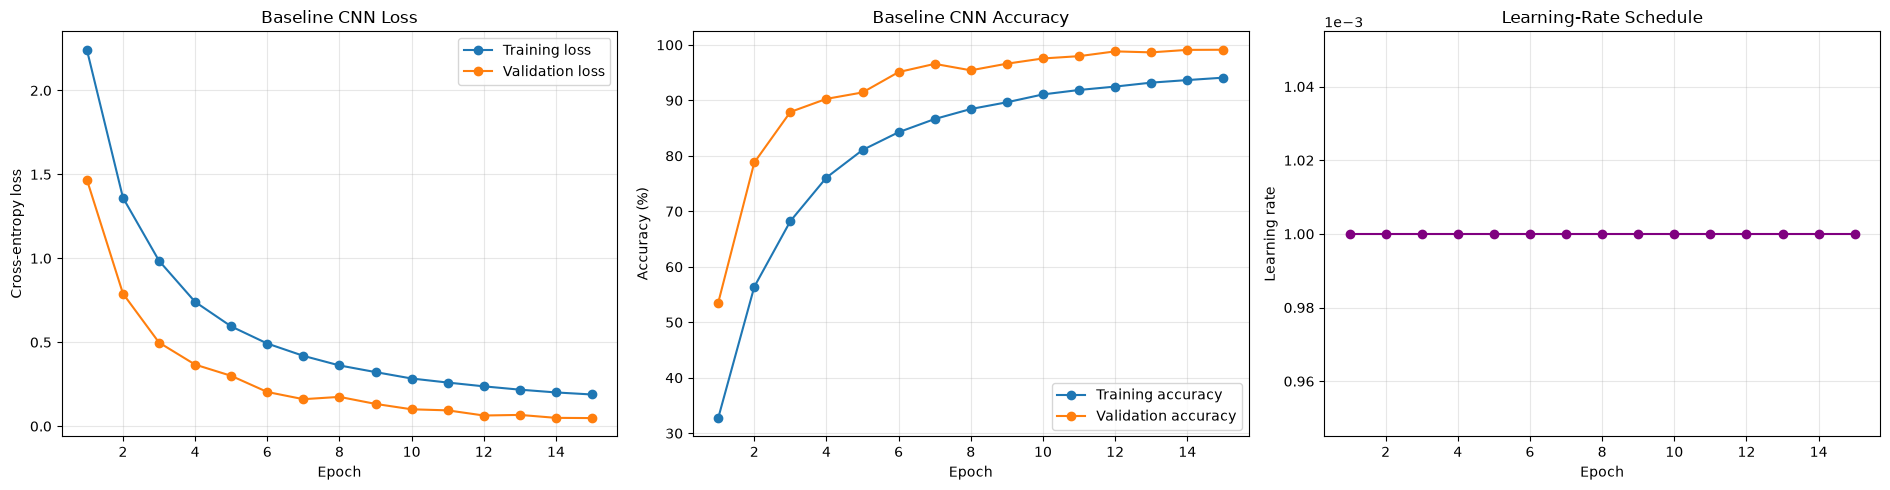

Best-model validation loss:     0.0482
Best-model validation accuracy: 99.13%
Validation images evaluated:    17,400


,precision,recall,f1-score,support
Class,,,,
N,0.990,0.957,0.973,600
M,0.957,0.992,0.974,600
U,0.960,0.997,0.978,600
V,0.988,0.968,0.978,600
B,1.000,0.963,0.981,600
W,0.977,0.997,0.987,600
G,0.979,0.997,0.988,600
H,1.000,0.977,0.988,600
T,0.977,1.000,0.988,600


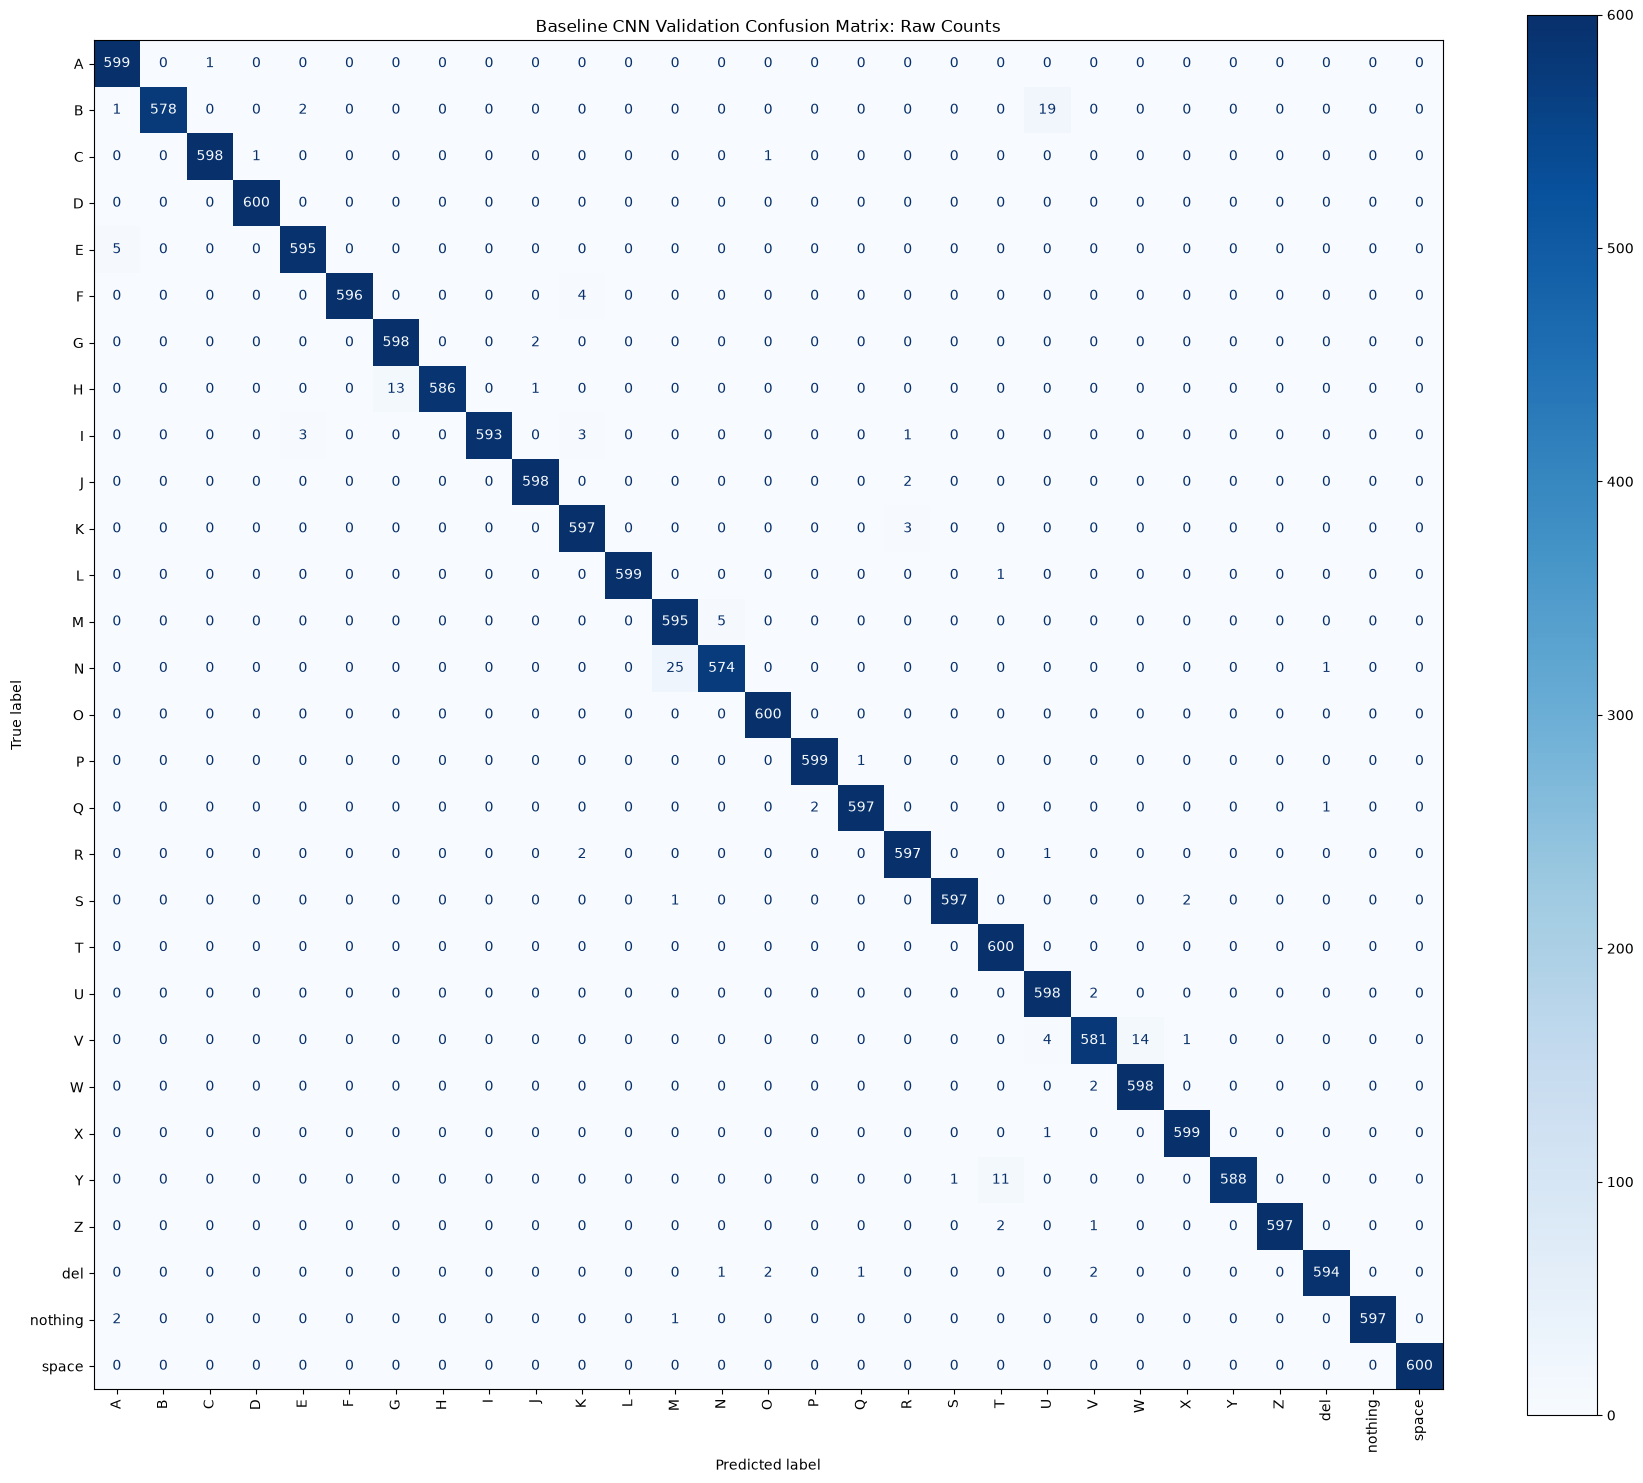

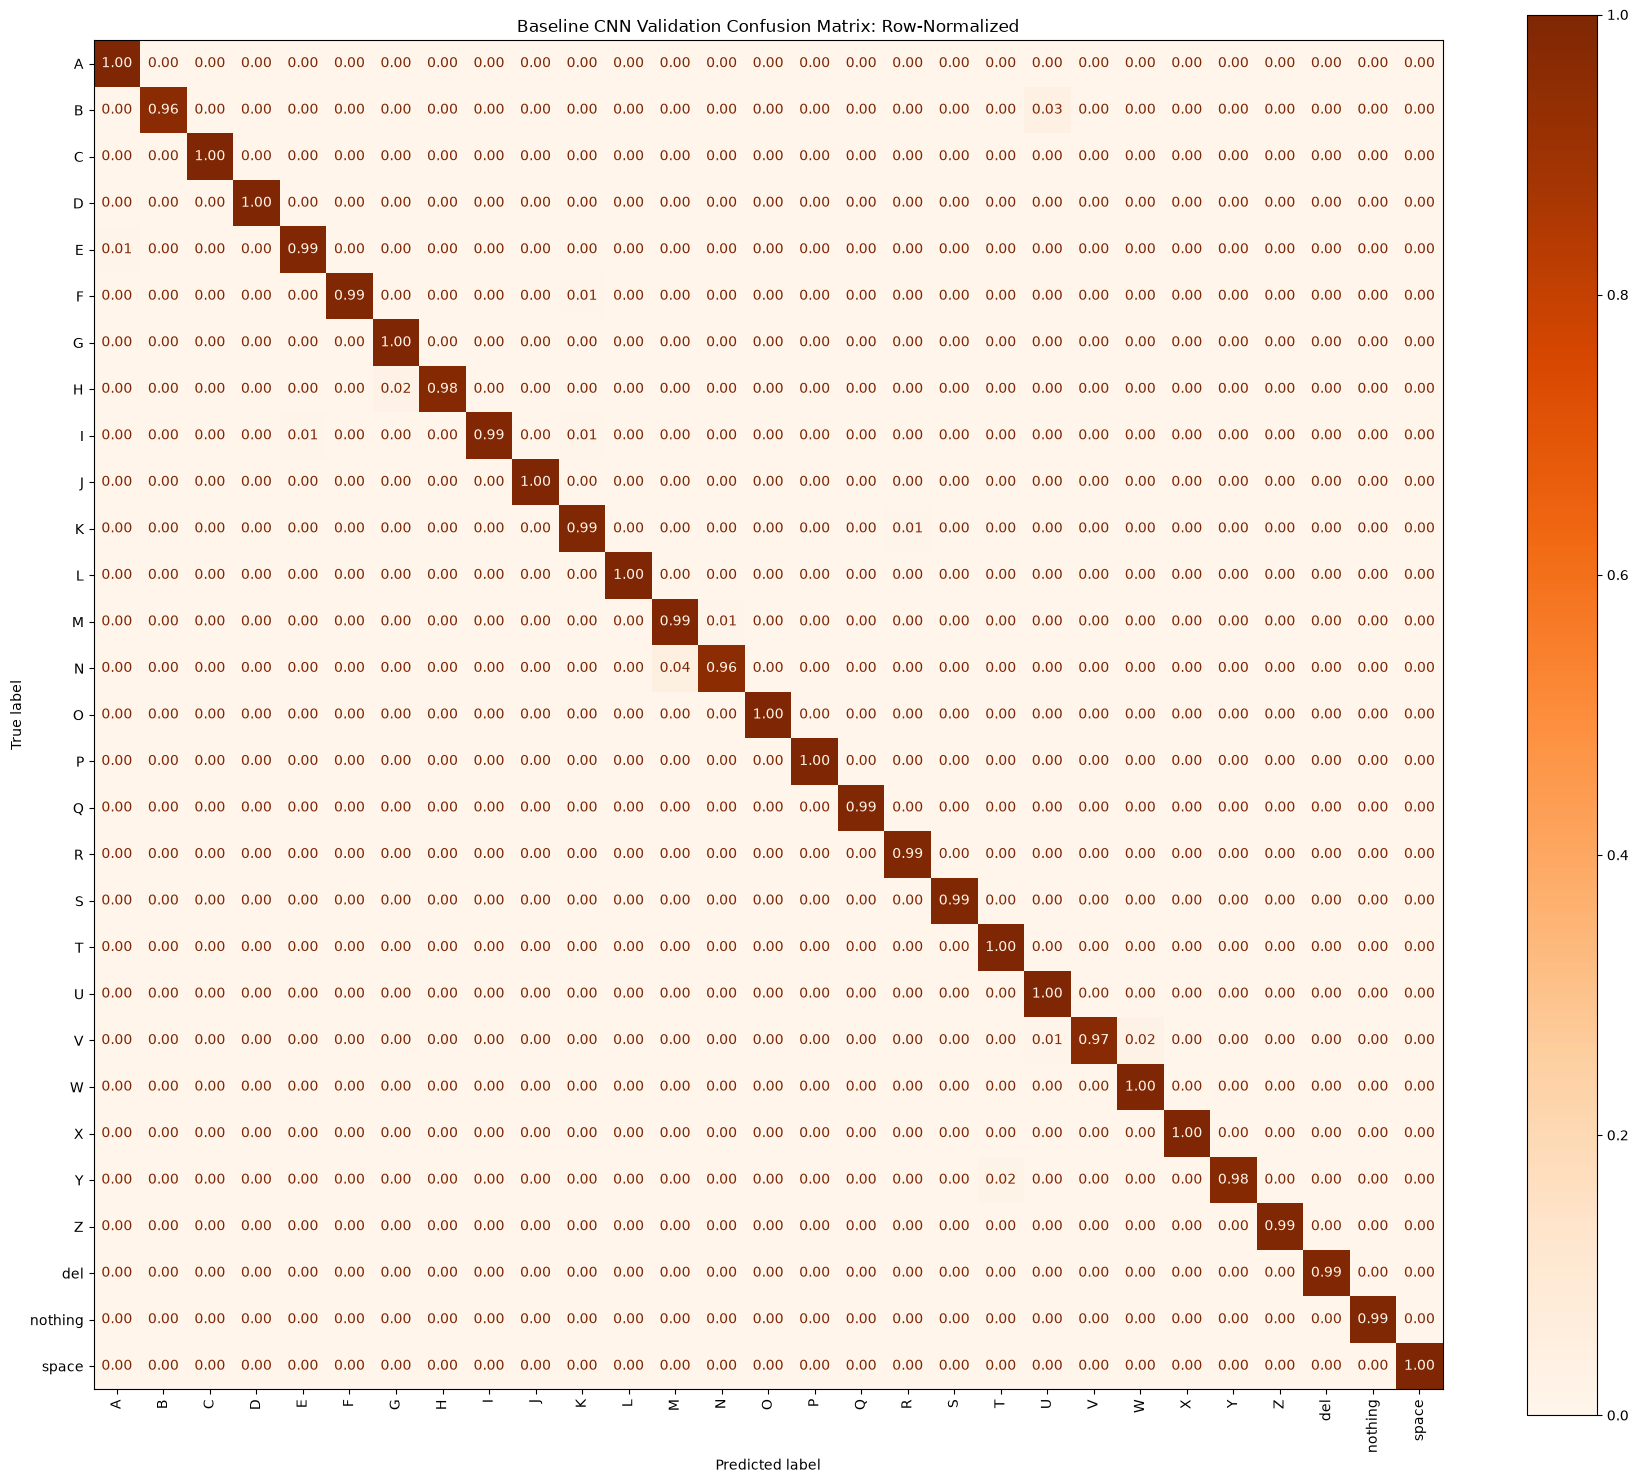

Ten most frequent incorrect validation predictions:


,Actual class,Predicted class,Incorrect predictions
0,N,M,25
1,B,U,19
2,V,W,14
3,H,G,13
4,Y,T,11
5,M,N,5
6,E,A,5
7,F,K,4
8,V,U,4
9,K,R,3


In [13]:
# Python Cell #12
# Expected runtime: about 2 minutes.
# Rerun status: Safe to rerun. It does not retrain the model, but it overwrites baseline-CNN result files in the artifacts/results folder. Rerun later comparison or export cells if you want them to use refreshed results.

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

assert baseline_best_checkpoint.exists(), (
    f"Best baseline model was not found:\n{baseline_best_checkpoint}\n"
    "Run Cell 11 successfully before running this evaluation cell."
)

best_baseline_model = BaselineCNN(num_classes=NUM_CLASSES).to(DEVICE)

best_baseline_state = load_training_checkpoint(
    checkpoint_path=baseline_best_checkpoint,
    model=best_baseline_model,
)

baseline_history_table = pd.DataFrame(baseline_history)
baseline_history_table.to_csv(
    RESULTS_DIR / "baseline_cnn_training_history.csv",
    index=False,
)

best_epoch_index = baseline_history_table["validation_accuracy"].idxmax()
best_epoch_row = baseline_history_table.loc[best_epoch_index]

summary_table = pd.DataFrame([{
    "Model": "Baseline CNN",
    "Best epoch": int(best_epoch_row["epoch"]),
    "Best validation accuracy": best_epoch_row["validation_accuracy"],
    "Validation loss at best epoch": best_epoch_row["validation_loss"],
    "Final training accuracy": baseline_history_table.iloc[-1]["training_accuracy"],
    "Total epochs completed": len(baseline_history_table),
    "Total training minutes": baseline_history_table["epoch_minutes"].sum(),
}])

display(summary_table.style.format({
    "Best validation accuracy": "{:.2%}",
    "Validation loss at best epoch": "{:.4f}",
    "Final training accuracy": "{:.2%}",
    "Total training minutes": "{:.1f}",
}))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    baseline_history_table["epoch"],
    baseline_history_table["training_loss"],
    marker="o",
    label="Training loss",
)
axes[0].plot(
    baseline_history_table["epoch"],
    baseline_history_table["validation_loss"],
    marker="o",
    label="Validation loss",
)
axes[0].set(
    title="Baseline CNN Loss",
    xlabel="Epoch",
    ylabel="Cross-entropy loss",
)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    baseline_history_table["epoch"],
    baseline_history_table["training_accuracy"] * 100,
    marker="o",
    label="Training accuracy",
)
axes[1].plot(
    baseline_history_table["epoch"],
    baseline_history_table["validation_accuracy"] * 100,
    marker="o",
    label="Validation accuracy",
)
axes[1].set(
    title="Baseline CNN Accuracy",
    xlabel="Epoch",
    ylabel="Accuracy (%)",
)
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(
    baseline_history_table["epoch"],
    baseline_history_table["learning_rate"],
    marker="o",
    color="purple",
)
axes[2].set(
    title="Learning-Rate Schedule",
    xlabel="Epoch",
    ylabel="Learning rate",
)
axes[2].grid(alpha=0.3)
axes[2].ticklabel_format(style="sci", axis="y", scilimits=(0, 0))

plt.tight_layout()
plt.show()

baseline_validation_metrics = evaluate_model(
    model=best_baseline_model,
    data_loader=validation_loader,
    loss_function=baseline_loss_function,
    collect_predictions=True,
)

print(f"Best-model validation loss:     {baseline_validation_metrics['loss']:.4f}")
print(f"Best-model validation accuracy: {baseline_validation_metrics['accuracy']:.2%}")
print(f"Validation images evaluated:    {baseline_validation_metrics['images_evaluated']:,}")

classification_report_table = pd.DataFrame(
    classification_report(
        baseline_validation_metrics["true_labels"],
        baseline_validation_metrics["predicted_labels"],
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
).transpose()

per_class_report = classification_report_table.loc[CLASS_NAMES].copy()
per_class_report.index.name = "Class"
per_class_report.to_csv(RESULTS_DIR / "baseline_cnn_classification_report.csv")

display(
    per_class_report
    .sort_values("f1-score")
    .style
    .format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1-score": "{:.3f}",
        "support": "{:.0f}",
    })
    .background_gradient(subset=["f1-score"], cmap="RdYlGn")
)

raw_confusion_matrix = confusion_matrix(
    baseline_validation_metrics["true_labels"],
    baseline_validation_metrics["predicted_labels"],
    labels=list(range(NUM_CLASSES)),
)

fig, ax = plt.subplots(figsize=(18, 15))
raw_display = ConfusionMatrixDisplay(
    confusion_matrix=raw_confusion_matrix,
    display_labels=CLASS_NAMES,
)
raw_display.plot(ax=ax, cmap="Blues", colorbar=True, xticks_rotation=90)
ax.set_title("Baseline CNN Validation Confusion Matrix: Raw Counts")
plt.tight_layout()
plt.show()

normalized_confusion_matrix = confusion_matrix(
    baseline_validation_metrics["true_labels"],
    baseline_validation_metrics["predicted_labels"],
    labels=list(range(NUM_CLASSES)),
    normalize="true",
)

fig, ax = plt.subplots(figsize=(18, 15))
normalized_display = ConfusionMatrixDisplay(
    confusion_matrix=normalized_confusion_matrix,
    display_labels=CLASS_NAMES,
)
normalized_display.plot(
    ax=ax,
    cmap="Oranges",
    colorbar=True,
    xticks_rotation=90,
    values_format=".2f",
)
ax.set_title("Baseline CNN Validation Confusion Matrix: Row-Normalized")
plt.tight_layout()
plt.show()

confusion_rows = []

for actual_index, actual_class in enumerate(CLASS_NAMES):
    for predicted_index, predicted_class in enumerate(CLASS_NAMES):
        count = raw_confusion_matrix[actual_index, predicted_index]

        if actual_index != predicted_index and count > 0:
            confusion_rows.append({
                "Actual class": actual_class,
                "Predicted class": predicted_class,
                "Incorrect predictions": count,
            })

top_confusions = (
    pd.DataFrame(confusion_rows)
    .sort_values("Incorrect predictions", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("Ten most frequent incorrect validation predictions:")
display(top_confusions)

summary_table.to_csv(RESULTS_DIR / "baseline_cnn_summary.csv", index=False)
top_confusions.to_csv(RESULTS_DIR / "baseline_cnn_top_confusions.csv", index=False)

# Markdown #13

### Purpose
This cell downloads or loads pretrained MobileNetV3-Small ImageNet weights, replaces its final output layer with a 29-class ASL classifier, freezes the pretrained visual-feature layers, and leaves its classifier layers trainable.

### Why it is needed
MobileNetV3-Small has already learned useful low-level visual features from a large image dataset. Transfer learning allows the model to adapt those learned features to ASL signs with substantially less training than a completely untrained model. Its performance will be compared against the custom baseline CNN.

In [14]:
# Python Cell #13
# Expected runtime: about 2 minutes the first time if pretrained weights must download; about 0 minutes afterward.
# Rerun status: Safe to rerun before MobileNet training begins. Rerunning this cell replaces mobilenet_model, so rerun all later MobileNet smoke-test, training, evaluation, and comparison cells afterward.

from torch import nn
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small
from torchvision.models import MobileNet_V3_Small_Weights, mobilenet_v3_small

MOBILENET_EPOCHS = 10
MOBILENET_LEARNING_RATE = 0.001
MOBILENET_WEIGHT_DECAY = 1e-4

MOBILENET_WEIGHTS = MobileNet_V3_Small_Weights.DEFAULT

def create_mobilenet_model():
    """
    Create a 29-class MobileNetV3-Small transfer-learning model.

    Pretrained feature layers are frozen initially. The classifier layers are
    trainable so they can learn the ASL-specific class decision boundaries.
    """
    try:
        model = mobilenet_v3_small(weights=MOBILENET_WEIGHTS)
    except Exception as error:
        raise RuntimeError(
            "Could not load the pretrained MobileNetV3-Small weights. "
            "Confirm that your computer has internet access for the initial "
            "download, then rerun this cell."
        ) from error

    # Freeze pretrained visual-feature layers.
    for parameter in model.features.parameters():
        parameter.requires_grad = False

    # Leave the classifier layers trainable.
    for parameter in model.classifier.parameters():
        parameter.requires_grad = True

    # Replace the original 1,000-class ImageNet output layer with 29 ASL classes.
    classifier_input_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(classifier_input_features, NUM_CLASSES)

    return model

mobilenet_model = create_mobilenet_model().to(DEVICE)

total_parameters = sum(parameter.numel() for parameter in mobilenet_model.parameters())
trainable_parameters = sum(
    parameter.numel()
    for parameter in mobilenet_model.parameters()
    if parameter.requires_grad
)
frozen_parameters = total_parameters - trainable_parameters

with torch.no_grad():
    test_input = torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    test_output = mobilenet_model(test_input)

mobilenet_parameter_table = pd.DataFrame([{
    "Model": "MobileNetV3-Small",
    "Total parameters": total_parameters,
    "Frozen pretrained parameters": frozen_parameters,
    "Trainable classifier parameters": trainable_parameters,
    "ASL output classes": NUM_CLASSES,
}])

display(
    mobilenet_parameter_table.style.format({
        "Total parameters": "{:,}",
        "Frozen pretrained parameters": "{:,}",
        "Trainable classifier parameters": "{:,}",
    })
)

print(f"Device:              {DEVICE}")
print(f"Verification input:  {tuple(test_input.shape)}")
print(f"Verification output: {tuple(test_output.shape)}")

assert test_output.shape == (2, NUM_CLASSES), (
    "The MobileNet output shape is incorrect. "
    f"Expected (2, {NUM_CLASSES}), received {tuple(test_output.shape)}."
)

,Model,Total parameters,Frozen pretrained parameters,Trainable classifier parameters,ASL output classes
0,MobileNetV3-Small,"1,547,581","927,008","620,573",29


Device:              cpu
Verification input:  (2, 3, 160, 160)
Verification output: (2, 29)


# Markdown #14

### Purpose
This cell performs a short MobileNet transfer-learning smoke test using a separate temporary model. It trains on 100 batches, evaluates 20 validation batches, saves test checkpoints, and estimates the time required for the complete MobileNet training run.

### Why it is needed
The baseline CNN required approximately eight hours to train. This test measures MobileNet performance using the same laptop, images, batch size, and data loader before starting its full run. It also verifies that the pretrained model, optimizer, GPU, validation process, and checkpoint system function correctly together.

In [15]:
# Python Cell #14
# Expected runtime: about 4 minutes.
# Rerun status: Safe to rerun. It trains only a separate MobileNet smoke-test model and overwrites only smoke-test checkpoints. No later MobileNet training or evaluation cells need to be rerun.

MOBILENET_SMOKE_TRAIN_BATCHES = 100
MOBILENET_SMOKE_VALIDATION_BATCHES = 20
MOBILENET_SMOKE_PROGRESS_INTERVAL = 25
MOBILENET_SMOKE_RUN_NAME = "mobilenet_smoke_test"

mobilenet_smoke_model = create_mobilenet_model().to(DEVICE)
mobilenet_smoke_loss_function = nn.CrossEntropyLoss()

mobilenet_smoke_optimizer = torch.optim.AdamW(
    filter(lambda parameter: parameter.requires_grad, mobilenet_smoke_model.parameters()),
    lr=MOBILENET_LEARNING_RATE,
    weight_decay=MOBILENET_WEIGHT_DECAY,
)

mobilenet_smoke_model.train()

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

train_start_time = time.perf_counter()
train_loss_total = 0.0
correct_predictions = 0
images_seen = 0

for batch_number, (images, labels) in enumerate(train_loader, start=1):
    images = images.to(DEVICE, non_blocking=PIN_MEMORY)
    labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)

    mobilenet_smoke_optimizer.zero_grad()

    logits = mobilenet_smoke_model(images)
    loss = mobilenet_smoke_loss_function(logits, labels)

    loss.backward()
    mobilenet_smoke_optimizer.step()

    train_loss_total += loss.item() * len(images)
    correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
    images_seen += len(images)

    if (
        batch_number % MOBILENET_SMOKE_PROGRESS_INTERVAL == 0
        or batch_number == MOBILENET_SMOKE_TRAIN_BATCHES
    ):
        elapsed_seconds = time.perf_counter() - train_start_time
        print(
            f"Training batch {batch_number:>3}/{MOBILENET_SMOKE_TRAIN_BATCHES} | "
            f"loss: {loss.item():.4f} | "
            f"elapsed: {elapsed_seconds / 60:.2f} minutes"
        )

    if batch_number == MOBILENET_SMOKE_TRAIN_BATCHES:
        break

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

train_elapsed_seconds = time.perf_counter() - train_start_time

validation_start_time = time.perf_counter()

mobilenet_smoke_validation_metrics = evaluate_model(
    model=mobilenet_smoke_model,
    data_loader=validation_loader,
    loss_function=mobilenet_smoke_loss_function,
    max_batches=MOBILENET_SMOKE_VALIDATION_BATCHES,
)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

validation_elapsed_seconds = time.perf_counter() - validation_start_time

mobilenet_smoke_training_metrics = {
    "loss": train_loss_total / images_seen,
    "accuracy": correct_predictions / images_seen,
    "images_evaluated": images_seen,
}

mobilenet_smoke_history = {
    "epoch": [1],
    "training_loss": [mobilenet_smoke_training_metrics["loss"]],
    "training_accuracy": [mobilenet_smoke_training_metrics["accuracy"]],
    "validation_loss": [mobilenet_smoke_validation_metrics["loss"]],
    "validation_accuracy": [mobilenet_smoke_validation_metrics["accuracy"]],
}

save_training_checkpoint(
    run_name=MOBILENET_SMOKE_RUN_NAME,
    checkpoint_name="last_checkpoint.pt",
    model=mobilenet_smoke_model,
    optimizer=mobilenet_smoke_optimizer,
    scheduler=None,
    epoch=1,
    batch=MOBILENET_SMOKE_TRAIN_BATCHES,
    history=mobilenet_smoke_history,
    best_validation_accuracy=mobilenet_smoke_validation_metrics["accuracy"],
    is_epoch_complete=True,
)

save_training_checkpoint(
    run_name=MOBILENET_SMOKE_RUN_NAME,
    checkpoint_name="best_model.pt",
    model=mobilenet_smoke_model,
    optimizer=mobilenet_smoke_optimizer,
    scheduler=None,
    epoch=1,
    batch=MOBILENET_SMOKE_TRAIN_BATCHES,
    history=mobilenet_smoke_history,
    best_validation_accuracy=mobilenet_smoke_validation_metrics["accuracy"],
    is_epoch_complete=True,
)

estimated_train_minutes_per_epoch = (
    train_elapsed_seconds / MOBILENET_SMOKE_TRAIN_BATCHES
    * len(train_loader)
    / 60
)

estimated_validation_minutes_per_epoch = (
    validation_elapsed_seconds / MOBILENET_SMOKE_VALIDATION_BATCHES
    * len(validation_loader)
    / 60
)

estimated_total_minutes = (
    estimated_train_minutes_per_epoch
    + estimated_validation_minutes_per_epoch
) * MOBILENET_EPOCHS

mobilenet_smoke_summary = pd.DataFrame([{
    "Device": str(DEVICE),
    "Smoke-test training images": mobilenet_smoke_training_metrics["images_evaluated"],
    "Smoke-test training accuracy": mobilenet_smoke_training_metrics["accuracy"],
    "Smoke-test validation accuracy": mobilenet_smoke_validation_metrics["accuracy"],
    "Estimated training minutes per epoch": estimated_train_minutes_per_epoch,
    "Estimated validation minutes per epoch": estimated_validation_minutes_per_epoch,
    "Planned MobileNet epochs": MOBILENET_EPOCHS,
    "Estimated total training minutes": estimated_total_minutes,
}])

display(
    mobilenet_smoke_summary.style.format({
        "Smoke-test training accuracy": "{:.2%}",
        "Smoke-test validation accuracy": "{:.2%}",
        "Estimated training minutes per epoch": "{:.1f}",
        "Estimated validation minutes per epoch": "{:.1f}",
        "Estimated total training minutes": "{:.1f}",
    })
)

print(f"Training loss:             {mobilenet_smoke_training_metrics['loss']:.4f}")
print(f"Validation loss:           {mobilenet_smoke_validation_metrics['loss']:.4f}")
print(f"Smoke-test checkpoints:    {CHECKPOINT_DIR / MOBILENET_SMOKE_RUN_NAME}")

Training batch  25/100 | loss: 2.5711 | elapsed: 0.09 minutes
Training batch  50/100 | loss: 1.6616 | elapsed: 0.19 minutes
Training batch  75/100 | loss: 1.6041 | elapsed: 0.29 minutes
Training batch 100/100 | loss: 1.3281 | elapsed: 0.39 minutes
Checkpoint saved: last_checkpoint.pt | epoch 1, batch 100, epoch complete: True
Checkpoint saved: best_model.pt | epoch 1, batch 100, epoch complete: True


,Device,Smoke-test training images,Smoke-test training accuracy,Smoke-test validation accuracy,Estimated training minutes per epoch,Estimated validation minutes per epoch,Planned MobileNet epochs,Estimated total training minutes
0,cpu,3200,42.59%,23.12%,8.5,1.0,10,94.4


Training loss:             2.0490
Validation loss:           2.3797
Smoke-test checkpoints:    c:\Users\Finnm\OneDrive - Cal Poly\Senior Year\ME 4452 - Machine Learning\Lab\Main Project\artifacts\checkpoints\mobilenet_smoke_test


# Markdown #15

### Purpose
This cell trains the MobileNetV3-Small transfer-learning model, evaluates validation performance after every epoch, saves a recoverable checkpoint every ten minutes, and saves the best model according to validation accuracy.

### Why it is needed
This is the main transfer-learning experiment. MobileNet performance will be compared against the custom baseline CNN so the final model selection is based on measured accuracy, class-level behavior, and training time rather than assumption.

In [16]:
# Python Cell #15
# Expected runtime: about the whole-number total-minute estimate reported by Python Cell 14 (297.1 minutes).
# Rerun status: Do not casually rerun. It starts a new MobileNet run or resumes an existing one, depending on RESUME_MOBILENET. Rerun Cell 16 after this cell completes or after training resumes.

MOBILENET_RUN_NAME = "mobilenet_classifier_run_01"
RESUME_MOBILENET = False
MOBILENET_PROGRESS_BATCH_INTERVAL = 100

mobilenet_run_dir = CHECKPOINT_DIR / MOBILENET_RUN_NAME
mobilenet_last_checkpoint = mobilenet_run_dir / "last_checkpoint.pt"
mobilenet_best_checkpoint = mobilenet_run_dir / "best_model.pt"

if "mobilenet_smoke_summary" in globals():
    estimated_total_minutes = round(
        mobilenet_smoke_summary.loc[0, "Estimated total training minutes"]
    )
    print(
        f"Cell 14 estimated approximately {estimated_total_minutes:,} minutes "
        f"for this {MOBILENET_EPOCHS}-epoch MobileNet run."
    )

mobilenet_model = create_mobilenet_model().to(DEVICE)
mobilenet_loss_function = nn.CrossEntropyLoss()

mobilenet_optimizer = torch.optim.AdamW(
    filter(lambda parameter: parameter.requires_grad, mobilenet_model.parameters()),
    lr=MOBILENET_LEARNING_RATE,
    weight_decay=MOBILENET_WEIGHT_DECAY,
)

mobilenet_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    mobilenet_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

mobilenet_history = {
    "epoch": [],
    "training_loss": [],
    "training_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "learning_rate": [],
    "epoch_minutes": [],
}

best_mobilenet_validation_accuracy = -float("inf")
mobilenet_start_epoch = 1

if RESUME_MOBILENET:
    assert mobilenet_last_checkpoint.exists(), (
        f"Resume was requested, but no checkpoint was found at:\n"
        f"{mobilenet_last_checkpoint}"
    )

    mobilenet_checkpoint_state = load_training_checkpoint(
        checkpoint_path=mobilenet_last_checkpoint,
        model=mobilenet_model,
        optimizer=mobilenet_optimizer,
        scheduler=mobilenet_scheduler,
    )

    mobilenet_history = mobilenet_checkpoint_state["history"]
    best_mobilenet_validation_accuracy = (
        mobilenet_checkpoint_state["best_validation_accuracy"]
    )

    if mobilenet_checkpoint_state["is_epoch_complete"]:
        mobilenet_start_epoch = mobilenet_checkpoint_state["epoch"] + 1
    else:
        # The model state is restored, while the unfinished epoch restarts.
        mobilenet_start_epoch = mobilenet_checkpoint_state["epoch"]

    print(f"Resuming MobileNet training from epoch {mobilenet_start_epoch}.")

else:
    assert not mobilenet_last_checkpoint.exists(), (
        f"A checkpoint already exists for '{MOBILENET_RUN_NAME}'.\n"
        "To continue that run, set RESUME_MOBILENET = True.\n"
        "To begin a separate run, change MOBILENET_RUN_NAME."
    )

    save_training_checkpoint(
        run_name=MOBILENET_RUN_NAME,
        checkpoint_name="last_checkpoint.pt",
        model=mobilenet_model,
        optimizer=mobilenet_optimizer,
        scheduler=mobilenet_scheduler,
        epoch=0,
        batch=0,
        history=mobilenet_history,
        best_validation_accuracy=best_mobilenet_validation_accuracy,
        is_epoch_complete=True,
    )

if mobilenet_start_epoch > MOBILENET_EPOCHS:
    print(
        f"MobileNet training is already complete through epoch {MOBILENET_EPOCHS}."
    )

else:
    mobilenet_overall_start_time = time.perf_counter()
    last_mobilenet_checkpoint_time = time.monotonic()
    current_mobilenet_epoch = mobilenet_start_epoch
    current_mobilenet_batch = 0

    try:
        for current_mobilenet_epoch in range(
            mobilenet_start_epoch,
            MOBILENET_EPOCHS + 1,
        ):
            epoch_start_time = time.perf_counter()

            mobilenet_model.train()

            # Keep pretrained feature layers and their BatchNorm statistics fixed.
            mobilenet_model.features.eval()

            training_loss_total = 0.0
            correct_predictions = 0
            images_seen = 0

            for current_mobilenet_batch, (images, labels) in enumerate(
                train_loader,
                start=1,
            ):
                images = images.to(DEVICE, non_blocking=PIN_MEMORY)
                labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)

                mobilenet_optimizer.zero_grad()

                logits = mobilenet_model(images)
                loss = mobilenet_loss_function(logits, labels)

                loss.backward()
                mobilenet_optimizer.step()

                training_loss_total += loss.item() * len(images)
                correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
                images_seen += len(images)

                elapsed_epoch_minutes = (
                    time.perf_counter() - epoch_start_time
                ) / 60

                if (
                    current_mobilenet_batch % MOBILENET_PROGRESS_BATCH_INTERVAL == 0
                ):
                    print(
                        f"Epoch {current_mobilenet_epoch:>2}/{MOBILENET_EPOCHS} | "
                        f"batch {current_mobilenet_batch:>4}/{len(train_loader)} | "
                        f"current loss: {loss.item():.4f} | "
                        f"elapsed: {elapsed_epoch_minutes:.1f} minutes"
                    )

                if (
                    time.monotonic() - last_mobilenet_checkpoint_time
                    >= CHECKPOINT_INTERVAL_SECONDS
                ):
                    save_training_checkpoint(
                        run_name=MOBILENET_RUN_NAME,
                        checkpoint_name="last_checkpoint.pt",
                        model=mobilenet_model,
                        optimizer=mobilenet_optimizer,
                        scheduler=mobilenet_scheduler,
                        epoch=current_mobilenet_epoch,
                        batch=current_mobilenet_batch,
                        history=mobilenet_history,
                        best_validation_accuracy=best_mobilenet_validation_accuracy,
                        is_epoch_complete=False,
                    )
                    last_mobilenet_checkpoint_time = time.monotonic()

            training_loss = training_loss_total / images_seen
            training_accuracy = correct_predictions / images_seen

            validation_metrics = evaluate_model(
                model=mobilenet_model,
                data_loader=validation_loader,
                loss_function=mobilenet_loss_function,
            )

            mobilenet_scheduler.step(validation_metrics["loss"])

            epoch_minutes = (time.perf_counter() - epoch_start_time) / 60
            current_learning_rate = mobilenet_optimizer.param_groups[0]["lr"]

            mobilenet_history["epoch"].append(current_mobilenet_epoch)
            mobilenet_history["training_loss"].append(training_loss)
            mobilenet_history["training_accuracy"].append(training_accuracy)
            mobilenet_history["validation_loss"].append(validation_metrics["loss"])
            mobilenet_history["validation_accuracy"].append(
                validation_metrics["accuracy"]
            )
            mobilenet_history["learning_rate"].append(current_learning_rate)
            mobilenet_history["epoch_minutes"].append(epoch_minutes)

            print(
                f"\nEpoch {current_mobilenet_epoch}/{MOBILENET_EPOCHS} complete | "
                f"train loss: {training_loss:.4f} | "
                f"train accuracy: {training_accuracy:.2%} | "
                f"validation loss: {validation_metrics['loss']:.4f} | "
                f"validation accuracy: {validation_metrics['accuracy']:.2%} | "
                f"time: {epoch_minutes:.1f} minutes\n"
            )

            save_training_checkpoint(
                run_name=MOBILENET_RUN_NAME,
                checkpoint_name="last_checkpoint.pt",
                model=mobilenet_model,
                optimizer=mobilenet_optimizer,
                scheduler=mobilenet_scheduler,
                epoch=current_mobilenet_epoch,
                batch=len(train_loader),
                history=mobilenet_history,
                best_validation_accuracy=best_mobilenet_validation_accuracy,
                is_epoch_complete=True,
            )
            last_mobilenet_checkpoint_time = time.monotonic()

            if validation_metrics["accuracy"] > best_mobilenet_validation_accuracy:
                best_mobilenet_validation_accuracy = validation_metrics["accuracy"]

                save_training_checkpoint(
                    run_name=MOBILENET_RUN_NAME,
                    checkpoint_name="best_model.pt",
                    model=mobilenet_model,
                    optimizer=mobilenet_optimizer,
                    scheduler=mobilenet_scheduler,
                    epoch=current_mobilenet_epoch,
                    batch=len(train_loader),
                    history=mobilenet_history,
                    best_validation_accuracy=best_mobilenet_validation_accuracy,
                    is_epoch_complete=True,
                )

                print(
                    f"New best MobileNet model saved with validation accuracy: "
                    f"{best_mobilenet_validation_accuracy:.2%}\n"
                )

        mobilenet_total_minutes = (
            time.perf_counter() - mobilenet_overall_start_time
        ) / 60

        print("MobileNet training complete.")
        print(
            f"Best validation accuracy: "
            f"{best_mobilenet_validation_accuracy:.2%}"
        )
        print(f"Total training time:      {mobilenet_total_minutes:.1f} minutes")
        print(f"Checkpoint folder:        {mobilenet_run_dir}")

    except KeyboardInterrupt:
        print("\nTraining interrupted. Saving the latest recoverable checkpoint...")

        save_training_checkpoint(
            run_name=MOBILENET_RUN_NAME,
            checkpoint_name="last_checkpoint.pt",
            model=mobilenet_model,
            optimizer=mobilenet_optimizer,
            scheduler=mobilenet_scheduler,
            epoch=current_mobilenet_epoch,
            batch=current_mobilenet_batch,
            history=mobilenet_history,
            best_validation_accuracy=best_mobilenet_validation_accuracy,
            is_epoch_complete=False,
        )

        print(
            "Checkpoint saved. To continue later, set RESUME_MOBILENET = True "
            "and rerun this cell."
        )
        raise

Cell 14 estimated approximately 94 minutes for this 10-epoch MobileNet run.
Checkpoint saved: last_checkpoint.pt | epoch 0, batch 0, epoch complete: True
Epoch  1/10 | batch  100/2175 | current loss: 0.9714 | elapsed: 0.3 minutes
Epoch  1/10 | batch  200/2175 | current loss: 0.4833 | elapsed: 0.7 minutes
Epoch  1/10 | batch  300/2175 | current loss: 0.3155 | elapsed: 1.0 minutes
Epoch  1/10 | batch  400/2175 | current loss: 0.2224 | elapsed: 1.3 minutes
Epoch  1/10 | batch  500/2175 | current loss: 0.4155 | elapsed: 1.7 minutes
Epoch  1/10 | batch  600/2175 | current loss: 0.3489 | elapsed: 2.0 minutes
Epoch  1/10 | batch  700/2175 | current loss: 0.2343 | elapsed: 2.4 minutes
Epoch  1/10 | batch  800/2175 | current loss: 0.2241 | elapsed: 2.7 minutes
Epoch  1/10 | batch  900/2175 | current loss: 0.1615 | elapsed: 3.1 minutes
Epoch  1/10 | batch 1000/2175 | current loss: 0.0884 | elapsed: 3.4 minutes
Epoch  1/10 | batch 1100/2175 | current loss: 0.1402 | elapsed: 3.7 minutes
Epoch  1/1

# Markdown #16

### Purpose
This cell loads the best saved MobileNet model, evaluates it on the complete validation set, creates MobileNet learning curves and confusion matrices, then compares MobileNet results with the saved baseline-CNN results.

### Why it is needed
This cell provides the evidence needed to choose the final model. It compares overall validation accuracy, loss, training time, per-class F1 scores, and frequent class confusions rather than relying on only one metric.

Loaded checkpoint: best_model.pt | saved 2026-10-30 19:03:40


,Model,Best epoch,Best validation accuracy,Validation loss at best epoch,Final training accuracy,Total epochs completed,Total training minutes
0,MobileNetV3-Small,9,97.61%,0.0855,98.48%,9,61.9


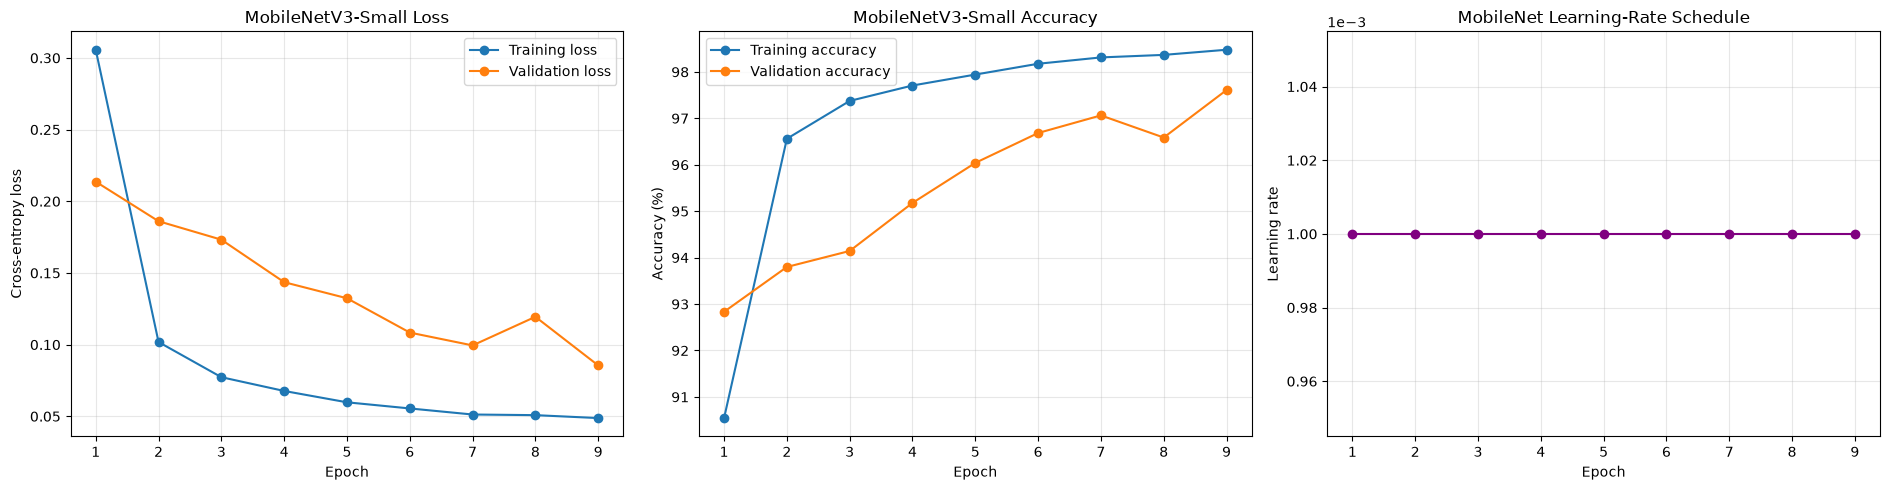

,precision,recall,f1-score,support
Class,,,,
U,0.965,0.872,0.916,600
V,0.964,0.885,0.923,600
R,0.914,0.952,0.932,600
W,0.964,0.948,0.956,600
Y,0.938,0.980,0.958,600
X,0.949,0.970,0.960,600
I,0.934,0.995,0.964,600
E,0.983,0.958,0.970,600
K,0.952,0.992,0.971,600


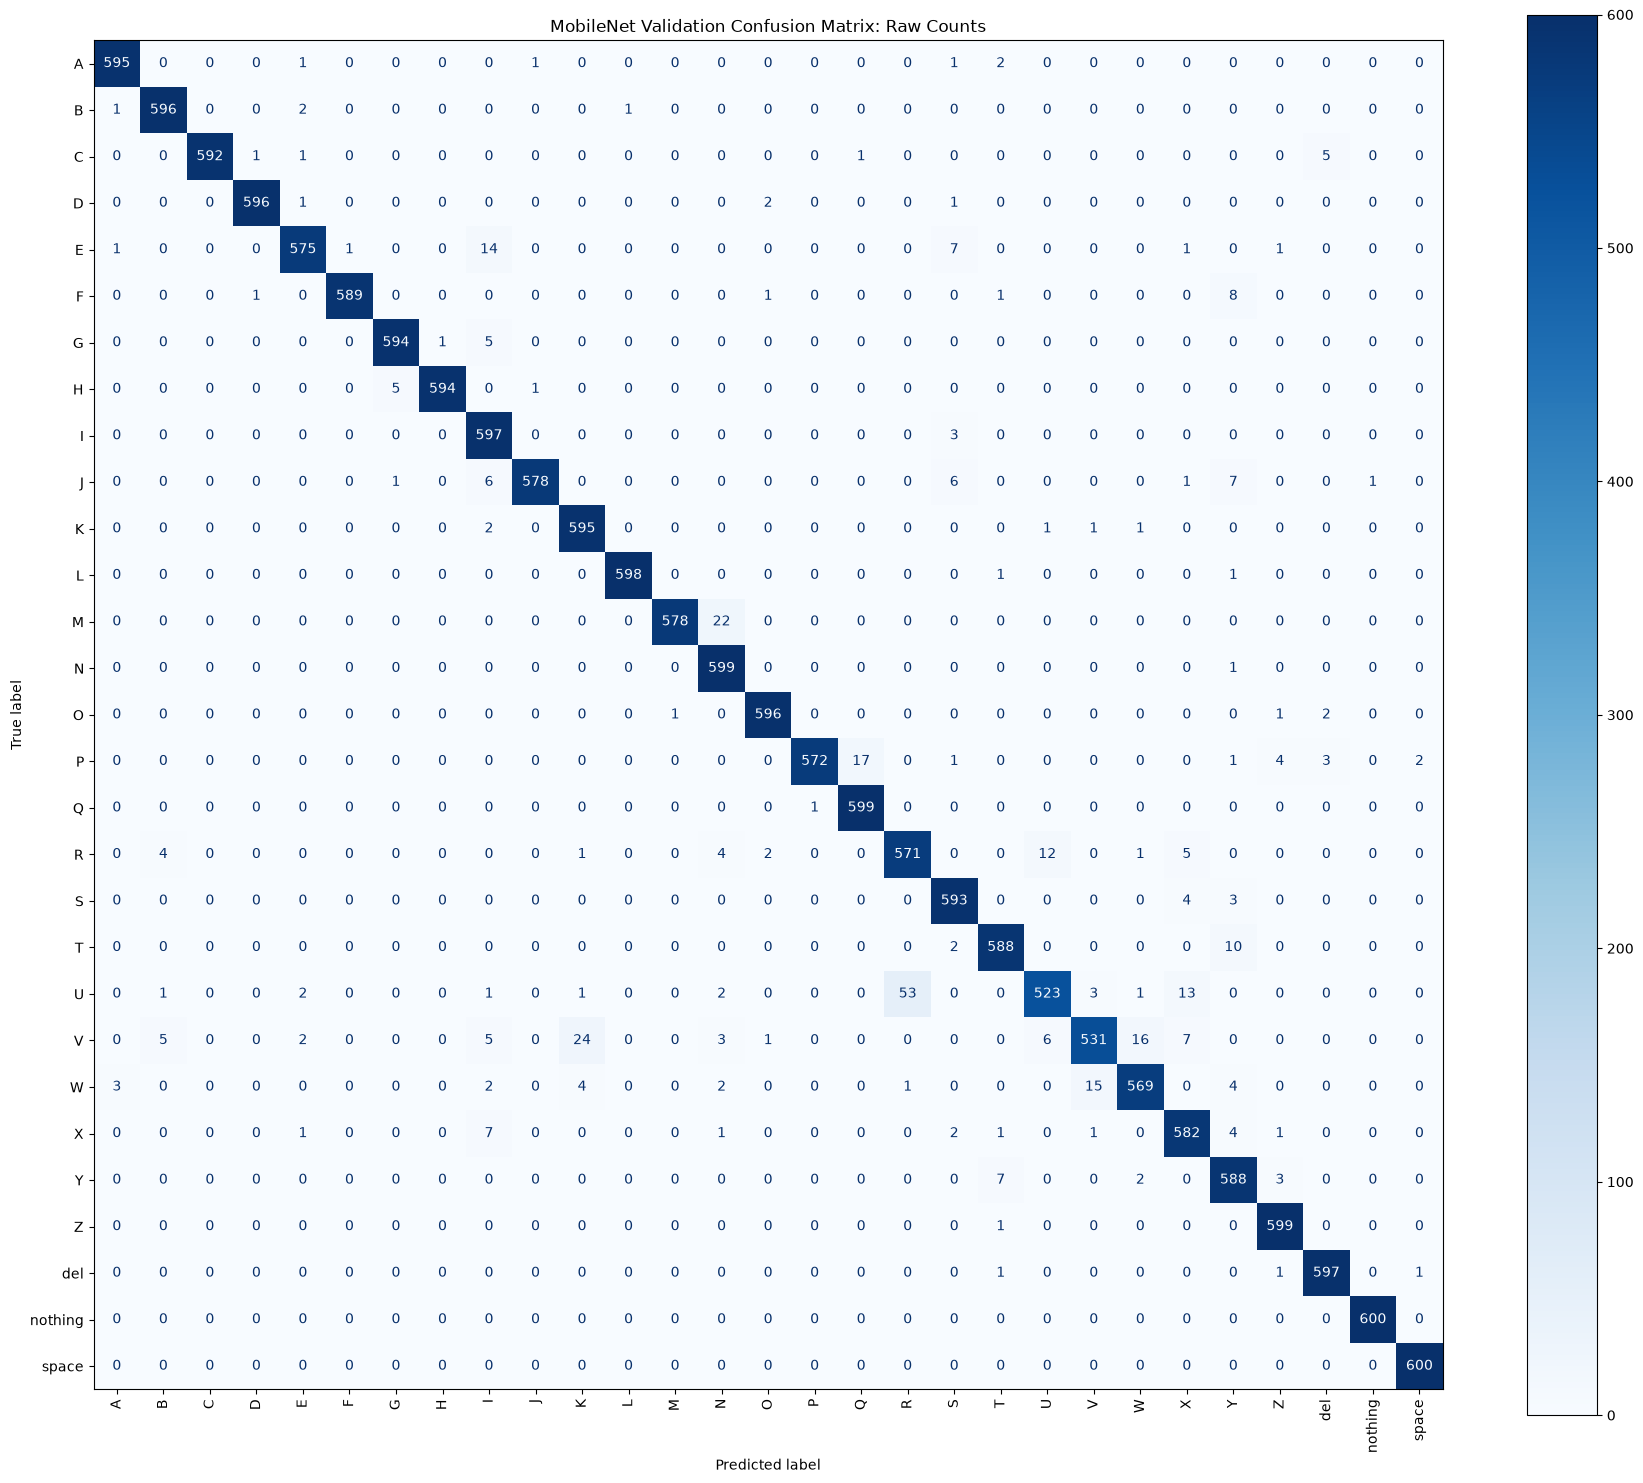

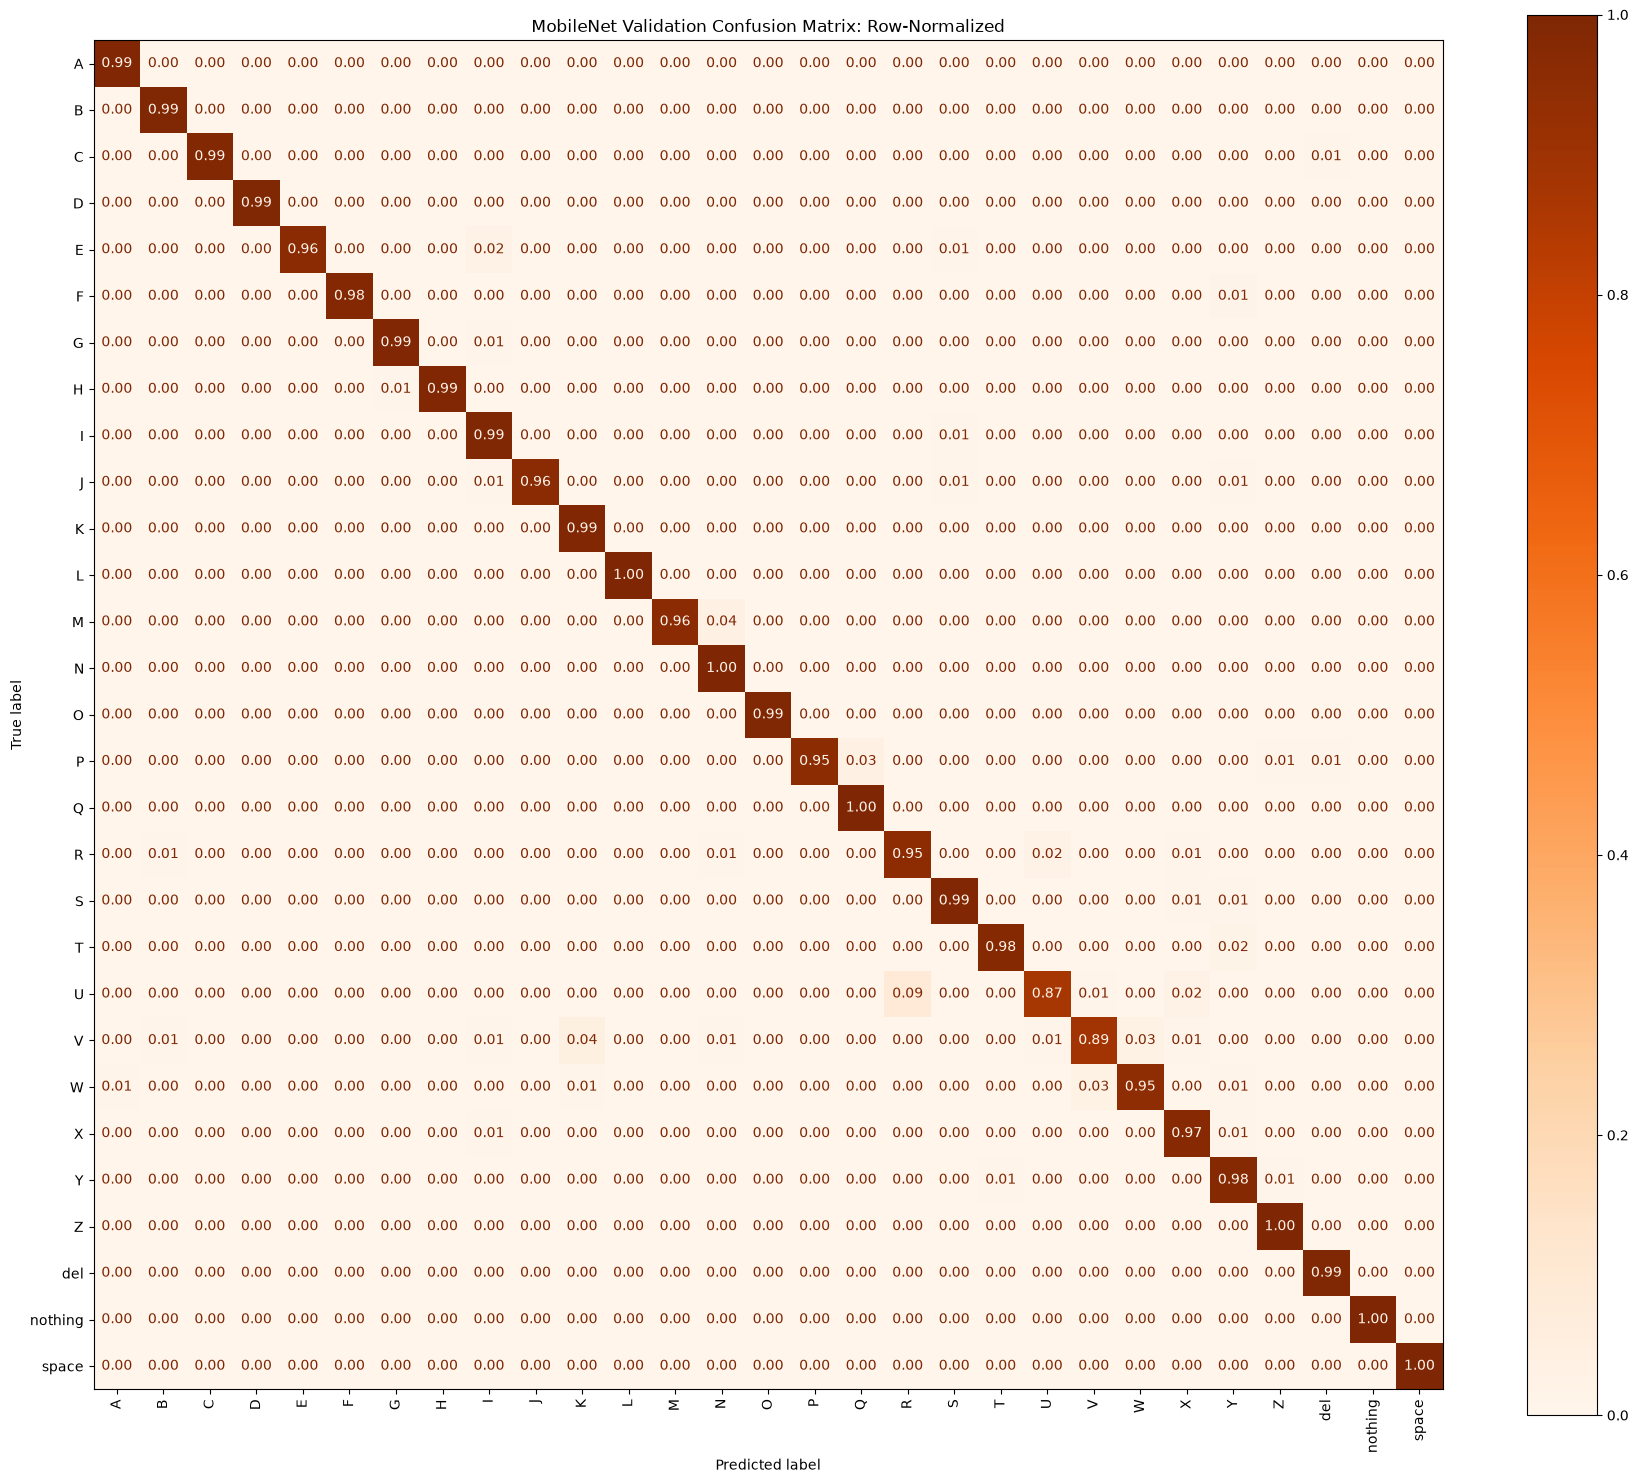

Ten most frequent incorrect MobileNet validation predictions:


,Actual class,Predicted class,Incorrect predictions
0,U,R,53
1,V,K,24
2,M,N,22
3,P,Q,17
4,V,W,16
5,W,V,15
6,E,I,14
7,U,X,13
8,R,U,12
9,T,Y,10


,Model,Best epoch,Best validation accuracy,Validation loss at best epoch,Final training accuracy,Total epochs completed,Total training minutes
0,Baseline CNN,15,99.13%,0.0482,94.10%,15,461.8
1,MobileNetV3-Small,9,97.61%,0.0855,98.48%,9,61.9


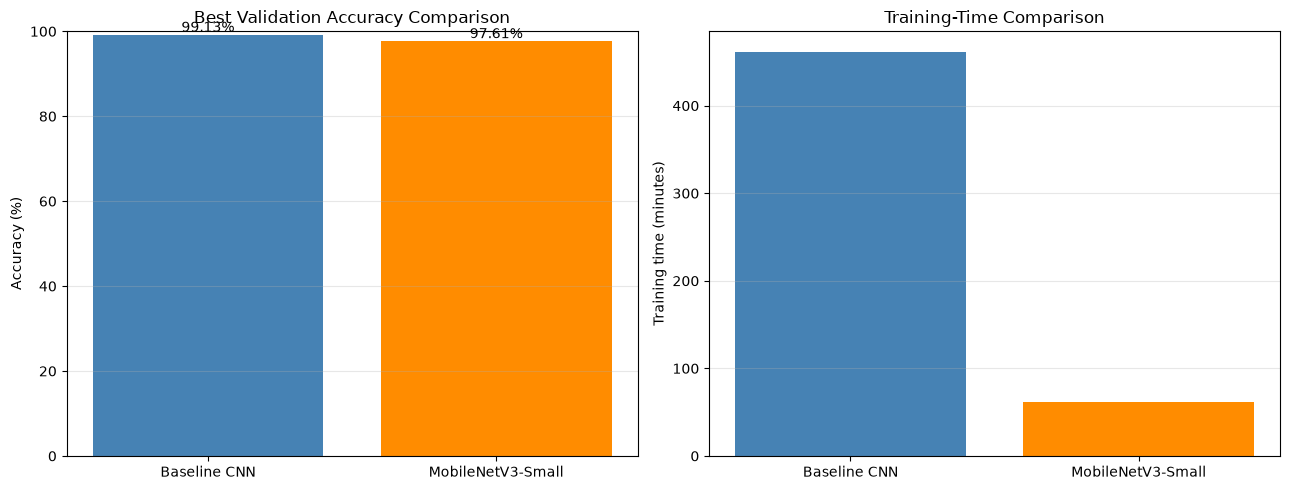

Per-class F1-score comparison, sorted from weakest to strongest MobileNet class:


,Baseline CNN F1 score,MobileNet F1 score,MobileNet - Baseline F1
Class,,,
U,0.978,0.916,-0.062
V,0.978,0.923,-0.055
R,0.993,0.932,-0.060
W,0.987,0.956,-0.030
Y,0.990,0.958,-0.031
X,0.997,0.960,-0.037
I,0.994,0.964,-0.030
E,0.992,0.970,-0.021
K,0.990,0.971,-0.019


In [17]:
# Python Cell #16
# Expected runtime: about 3 minutes.
# Rerun status: Safe to rerun. It does not retrain either model, but it overwrites MobileNet and model-comparison result files in the artifacts/results folder. Rerun later final-model-selection and test-evaluation cells if these results change.

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)

assert mobilenet_best_checkpoint.exists(), (
    f"Best MobileNet model was not found:\n{mobilenet_best_checkpoint}\n"
    "Run Python Cell 15 successfully before running this evaluation cell."
)

baseline_summary_path = RESULTS_DIR / "baseline_cnn_summary.csv"
baseline_class_report_path = RESULTS_DIR / "baseline_cnn_classification_report.csv"

assert baseline_summary_path.exists(), (
    "The saved baseline-CNN summary was not found. "
    "Run Python Cell 12 before running this comparison cell."
)

best_mobilenet_model = create_mobilenet_model().to(DEVICE)

best_mobilenet_state = load_training_checkpoint(
    checkpoint_path=mobilenet_best_checkpoint,
    model=best_mobilenet_model,
)

mobilenet_history = best_mobilenet_state["history"]
mobilenet_history_table = pd.DataFrame(mobilenet_history)

mobilenet_history_table.to_csv(
    RESULTS_DIR / "mobilenet_training_history.csv",
    index=False,
)

best_epoch_index = mobilenet_history_table["validation_accuracy"].idxmax()
best_epoch_row = mobilenet_history_table.loc[best_epoch_index]

mobilenet_validation_metrics = evaluate_model(
    model=best_mobilenet_model,
    data_loader=validation_loader,
    loss_function=nn.CrossEntropyLoss(),
    collect_predictions=True,
)

mobilenet_summary_table = pd.DataFrame([{
    "Model": "MobileNetV3-Small",
    "Best epoch": int(best_epoch_row["epoch"]),
    "Best validation accuracy": mobilenet_validation_metrics["accuracy"],
    "Validation loss at best epoch": mobilenet_validation_metrics["loss"],
    "Final training accuracy": mobilenet_history_table.iloc[-1]["training_accuracy"],
    "Total epochs completed": len(mobilenet_history_table),
    "Total training minutes": mobilenet_history_table["epoch_minutes"].sum(),
}])

mobilenet_summary_table.to_csv(
    RESULTS_DIR / "mobilenet_summary.csv",
    index=False,
)

display(
    mobilenet_summary_table.style.format({
        "Best validation accuracy": "{:.2%}",
        "Validation loss at best epoch": "{:.4f}",
        "Final training accuracy": "{:.2%}",
        "Total training minutes": "{:.1f}",
    })
)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(
    mobilenet_history_table["epoch"],
    mobilenet_history_table["training_loss"],
    marker="o",
    label="Training loss",
)
axes[0].plot(
    mobilenet_history_table["epoch"],
    mobilenet_history_table["validation_loss"],
    marker="o",
    label="Validation loss",
)
axes[0].set(
    title="MobileNetV3-Small Loss",
    xlabel="Epoch",
    ylabel="Cross-entropy loss",
)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    mobilenet_history_table["epoch"],
    mobilenet_history_table["training_accuracy"] * 100,
    marker="o",
    label="Training accuracy",
)
axes[1].plot(
    mobilenet_history_table["epoch"],
    mobilenet_history_table["validation_accuracy"] * 100,
    marker="o",
    label="Validation accuracy",
)
axes[1].set(
    title="MobileNetV3-Small Accuracy",
    xlabel="Epoch",
    ylabel="Accuracy (%)",
)
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(
    mobilenet_history_table["epoch"],
    mobilenet_history_table["learning_rate"],
    marker="o",
    color="purple",
)
axes[2].set(
    title="MobileNet Learning-Rate Schedule",
    xlabel="Epoch",
    ylabel="Learning rate",
)
axes[2].grid(alpha=0.3)
axes[2].ticklabel_format(style="sci", axis="y", scilimits=(0, 0))

plt.tight_layout()
plt.savefig(RESULTS_DIR / "mobilenet_training_curves.png", dpi=200)
plt.show()

mobilenet_classification_report = pd.DataFrame(
    classification_report(
        mobilenet_validation_metrics["true_labels"],
        mobilenet_validation_metrics["predicted_labels"],
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
).transpose()

mobilenet_per_class_report = mobilenet_classification_report.loc[CLASS_NAMES].copy()
mobilenet_per_class_report.index.name = "Class"

mobilenet_per_class_report.to_csv(
    RESULTS_DIR / "mobilenet_classification_report.csv"
)

display(
    mobilenet_per_class_report
    .sort_values("f1-score")
    .style
    .format({
        "precision": "{:.3f}",
        "recall": "{:.3f}",
        "f1-score": "{:.3f}",
        "support": "{:.0f}",
    })
    .background_gradient(subset=["f1-score"], cmap="RdYlGn")
)

mobilenet_confusion_matrix = confusion_matrix(
    mobilenet_validation_metrics["true_labels"],
    mobilenet_validation_metrics["predicted_labels"],
    labels=list(range(NUM_CLASSES)),
)

fig, ax = plt.subplots(figsize=(18, 15))
raw_display = ConfusionMatrixDisplay(
    confusion_matrix=mobilenet_confusion_matrix,
    display_labels=CLASS_NAMES,
)
raw_display.plot(ax=ax, cmap="Blues", colorbar=True, xticks_rotation=90)
ax.set_title("MobileNet Validation Confusion Matrix: Raw Counts")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mobilenet_confusion_matrix_raw.png", dpi=200)
plt.show()

normalized_mobilenet_confusion_matrix = confusion_matrix(
    mobilenet_validation_metrics["true_labels"],
    mobilenet_validation_metrics["predicted_labels"],
    labels=list(range(NUM_CLASSES)),
    normalize="true",
)

fig, ax = plt.subplots(figsize=(18, 15))
normalized_display = ConfusionMatrixDisplay(
    confusion_matrix=normalized_mobilenet_confusion_matrix,
    display_labels=CLASS_NAMES,
)
normalized_display.plot(
    ax=ax,
    cmap="Oranges",
    colorbar=True,
    xticks_rotation=90,
    values_format=".2f",
)
ax.set_title("MobileNet Validation Confusion Matrix: Row-Normalized")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mobilenet_confusion_matrix_normalized.png", dpi=200)
plt.show()

mobilenet_confusion_rows = []

for actual_index, actual_class in enumerate(CLASS_NAMES):
    for predicted_index, predicted_class in enumerate(CLASS_NAMES):
        incorrect_count = mobilenet_confusion_matrix[actual_index, predicted_index]

        if actual_index != predicted_index and incorrect_count > 0:
            mobilenet_confusion_rows.append({
                "Actual class": actual_class,
                "Predicted class": predicted_class,
                "Incorrect predictions": incorrect_count,
            })

mobilenet_top_confusions = (
    pd.DataFrame(mobilenet_confusion_rows)
    .sort_values("Incorrect predictions", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("Ten most frequent incorrect MobileNet validation predictions:")
display(mobilenet_top_confusions)

mobilenet_top_confusions.to_csv(
    RESULTS_DIR / "mobilenet_top_confusions.csv",
    index=False,
)

baseline_summary_table = pd.read_csv(baseline_summary_path)

model_comparison_table = pd.concat(
    [baseline_summary_table, mobilenet_summary_table],
    ignore_index=True,
)

display(
    model_comparison_table.style.format({
        "Best validation accuracy": "{:.2%}",
        "Validation loss at best epoch": "{:.4f}",
        "Final training accuracy": "{:.2%}",
        "Total training minutes": "{:.1f}",
    })
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    model_comparison_table["Model"],
    model_comparison_table["Best validation accuracy"] * 100,
    color=["steelblue", "darkorange"],
)
axes[0].set(
    title="Best Validation Accuracy Comparison",
    ylabel="Accuracy (%)",
    ylim=(0, 100),
)
axes[0].grid(axis="y", alpha=0.3)

for bar in axes[0].patches:
    axes[0].annotate(
        f"{bar.get_height():.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
    )

axes[1].bar(
    model_comparison_table["Model"],
    model_comparison_table["Total training minutes"],
    color=["steelblue", "darkorange"],
)
axes[1].set(
    title="Training-Time Comparison",
    ylabel="Training time (minutes)",
)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "baseline_vs_mobilenet_comparison.png", dpi=200)
plt.show()

if baseline_class_report_path.exists():
    baseline_per_class_report = (
        pd.read_csv(baseline_class_report_path)
        .set_index("Class")
    )

    per_class_f1_comparison = pd.DataFrame({
        "Baseline CNN F1 score": baseline_per_class_report["f1-score"],
        "MobileNet F1 score": mobilenet_per_class_report["f1-score"],
    })

    per_class_f1_comparison["MobileNet - Baseline F1"] = (
        per_class_f1_comparison["MobileNet F1 score"]
        - per_class_f1_comparison["Baseline CNN F1 score"]
    )

    print("Per-class F1-score comparison, sorted from weakest to strongest MobileNet class:")
    display(
        per_class_f1_comparison
        .sort_values("MobileNet F1 score")
        .style
        .format("{:.3f}")
        .background_gradient(
            subset=["MobileNet - Baseline F1"],
            cmap="RdYlGn",
        )
    )

    per_class_f1_comparison.to_csv(
        RESULTS_DIR / "baseline_vs_mobilenet_per_class_f1.csv"
    )

model_comparison_table.to_csv(
    RESULTS_DIR / "baseline_vs_mobilenet_summary.csv",
    index=False,
)